In [2]:
import numpy as np

import sympy as sp

from sympy import sin
import time
import math

from utils import ( 
        get_fitted_scaler_from_csv, 
        clean_point, 
        symbolic_gradient, 
        mean_absolute_error_numpy, 
        get_distances_and_features_ckdtree,
        calculate_weight_matrix,
        predict_gibbs_energy_arrays,
        get_neighbors,
        COLUMN_TO_VAR
)

# Example usage
file_path = "/home/couchbucks/Documents/saketh/regression/regression/718_all/718_all.csv"
target_col = 'Gibbs_energy'
x_scaler, y_scaler, scaled_df = get_fitted_scaler_from_csv(file_path, target_col, scale_data=True)
_, _, true_df = get_fitted_scaler_from_csv(file_path, target_col, scale_data=False)

/home/couchbucks/Documents/saketh/regression/regression/utils.py:158: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)
/home/couchbucks/Documents/saketh/regression/regression/utils.py:158: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)


In [3]:
vars(y_scaler)

{'mean_': array([-91140.3713128]), 'scale_': array([22724.9440497])}

In [4]:
import pickle

model_path = '/home/couchbucks/Documents/saketh/regression/regression/718_all/train_results/saved_models/Linear Regression/Linear Regression_1/Linear Regression_1.pkl'
try:
    with open(model_path, 'rb') as file:
        model = pickle.load(file)
        # print("Data successfully unpickled:")
except FileNotFoundError:
    print(f"The file at {model_path} was not found.")
except pickle.UnpicklingError:
    print("Error unpickling the file.")
except Exception as e:
    print(f"An error occurred: {e}")

/home/couchbucks/Documents/saketh/regression/env/lib/python3.12/site-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator LinearRegression from version 1.5.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [5]:
scaled_df

,Mass_fraction_Nb,Mass_fraction_Al,Mass_fraction_Ti,Mass_fraction_Mo,Mass_fraction_Fe,Mass_fraction_Ni,Mass_fraction_Cr,Temperature_[K],temp_class,Gibbs_energy
0,-1.379729,-0.285699,-0.408702,-0.367397,-0.051609,NaN,-0.179212,-1.710798,nb,1.843888
1,-1.379729,-0.285699,-0.408702,-0.367397,-0.051609,NaN,-0.179212,-1.668028,nb,1.807418
2,-1.379729,-0.285699,-0.408702,-0.367397,-0.051609,NaN,-0.179212,-1.625258,nb,1.770809
3,-1.379729,-0.285699,-0.408702,-0.367397,-0.051609,NaN,-0.179212,-1.582488,nb,1.734061
4,-1.379729,-0.285699,-0.408702,-0.367397,-0.051609,NaN,-0.179212,-1.539718,nb,1.697175
...,...,...,...,...,...,...,...,...,...,...
8176,-0.384353,-0.285699,-0.408702,-0.367397,-0.051609,NaN,5.579997,1.539718,cr,-1.344189
8177,-0.384353,-0.285699,-0.408702,-0.367397,-0.051609,NaN,5.579997,1.582488,cr,-1.390042
8178,-0.384353,-0.285699,-0.408702,-0.367397,-0.051609,NaN,5.579997,1.625258,cr,-1.435983
8179,-0.384353,-0.285699,-0.408702,-0.367397,-0.051609,NaN,5.579997,1.668028,cr,-1.482012


In [6]:
import pandas as pd

from sklearn.preprocessing import StandardScaler, MinMaxScaler

SCALER_DISPATCH = {
    'standard': StandardScaler,
    'min_max': MinMaxScaler
}

def basic_preprocess_data(df, data_scaler):
    target_column = None
    for col in df.columns:
        if 'gibbs energy' in col.lower() or 'gibbs_energy' in col.lower():
            target_column = col
            break
    
    if target_column is None:
        raise ValueError("No target column containing 'gibbs energy' found.")
    
    # print(target_column)
    # print('\n')
    
    y = df[target_column]
    X = df.drop(columns=[target_column])
    
    # print(df)
    # print('\n')
    # print(y)
    # print('\n')
    # print(X)
    
    for col in X.columns:
        if not pd.api.types.is_numeric_dtype(X[col]):
            X[col] = X[col].astype('category').cat.codes

    X = X.values
    y = y.values
    
    if data_scaler != '':
        # print(X)
        X = SCALER_DISPATCH[data_scaler]().fit_transform(X)

        y_2d = np.reshape(y, (y.shape[0], 1))
        y = SCALER_DISPATCH[data_scaler]().fit_transform(y_2d).flatten()

    return X, y

In [7]:
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error


target_column = 'Gibbs_energy'

# y = scaled_df[target_column]
    
# # Drop the target column from features
# X = scaled_df.drop(columns=[target_column])

# # Encode quantitative variables
# for col in X.columns:
#     if not pd.api.types.is_numeric_dtype(X[col]):
        
#         # Assign integer values ranging from 0 to n-1
#         X[col] = X[col].astype('category').cat.codes

X, y = basic_preprocess_data(scaled_df, 'standard')

from sklearn.model_selection import train_test_split


x_train, x_test, y_train, y_test = train_test_split(
        X, 
        y, 
        test_size=0.2,  
        random_state=42  # Seed for reproducibility, changes each split
    )

# x_test = x_test.drop(columns=['Mass_fraction_Ni'])

x_train = np.nan_to_num(x_train, nan=0.0)

x_test = np.nan_to_num(x_test, nan=0.0)




/home/couchbucks/Documents/saketh/regression/env/lib/python3.12/site-packages/sklearn/utils/extmath.py:1101: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
/home/couchbucks/Documents/saketh/regression/env/lib/python3.12/site-packages/sklearn/utils/extmath.py:1106: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
/home/couchbucks/Documents/saketh/regression/env/lib/python3.12/site-packages/sklearn/utils/extmath.py:1126: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


In [8]:
# from sklearn.neural_network import MLPRegressor

# temp_model = MLPRegressor(
#             hidden_layer_sizes=(100,),
#             activation='relu',
#             solver='adam',
#             max_iter=200,
#             random_state=1
#         )

In [9]:
# temp_model.fit(x_train, y_train)

In [10]:
# y_train_pred = model.predict(x_train)
start = time.perf_counter()
y_test_pred = model.predict(x_test)
end = time.perf_counter()

print(end-start)

0.0009023629972944036


In [11]:
x_train.shape

(6544, 9)

In [12]:
x_test.shape

(1637, 9)

In [13]:
y_pred_non_std = y_scaler.inverse_transform(y_test_pred)

In [14]:
target_column = 'Gibbs_energy'

y = true_df[target_column]
    
# Drop the target column from features
X = true_df.drop(columns=[target_column])

# Encode quantitative variables
for col in X.columns:
    if not pd.api.types.is_numeric_dtype(X[col]):
        
        # Assign integer values ranging from 0 to n-1
        X[col] = X[col].astype('category').cat.codes
        
from sklearn.model_selection import train_test_split


x_train, x_test, y_train, y_test_non_std = train_test_split(
        X, 
        y, 
        test_size=0.2,  
        random_state=42  # Seed for reproducibility, changes each split
    )

In [15]:
non_zero_indices = y_test != 0
abs_percentage_errors = np.abs((y_test[non_zero_indices] - y_test_pred[non_zero_indices]) / y_test[non_zero_indices])
mape = mean_absolute_percentage_error(y_true=y_test_non_std, y_pred=y_pred_non_std)

mae_test = mean_absolute_error(y_test_non_std, y_pred_non_std)

mape_stdev = np.std(abs_percentage_errors)

decimals = 7


print(f"Mean Absolute Error (MAE): {mae_test:.{decimals}f}")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.{decimals}f} ± {2 * mape_stdev:.{decimals}f}")

Mean Absolute Error (MAE): 922.4312385
Mean Absolute Percentage Error (MAPE): 0.0105114 ± 2.7400477


In [16]:
import numpy as np

def split_and_process_dataframe(
    scaled_df, 
    column_order, 
    column_to_var, 
    target_column, 
    sample_fraction=0.8, 
    random_state=42, 
    clean_fn=None
):
    """
    Splits the DataFrame into reference and query datasets, processes the columns, 
    and converts them to NumPy arrays.
    
    Parameters:
        scaled_df (pd.DataFrame): The input DataFrame to be split and processed.
        column_order (list): The desired column order for processing.
        column_to_var (dict): Mapping of column names to variable names.
        target_column (str): The name of the target column (e.g., 'Gibbs_energy').
        sample_fraction (float): Fraction of rows to use for the reference set (default 0.8).
        random_state (int): Random seed for reproducibility (default 42).
        clean_fn (callable): Function to clean/transform rows; defaults to identity function.
        
    Returns:
        tuple: (ref_points, query_points, ref_target, query_target)
            - ref_points: NumPy array of reference points.
            - query_points: NumPy array of query points.
            - ref_target: NumPy array of target values for the reference set.
            - query_target: NumPy array of target values for the query set.
    """
    if clean_fn is None:
        clean_fn = lambda x: x  # Default to no cleaning
    
    # Calculate the number of rows to sample
    sample_size = int(len(scaled_df) * sample_fraction)
    
    # Randomly sample rows for the reference set
    reference_df = scaled_df.sample(n=sample_size, random_state=random_state)
    
    # Extract the target column and reformat the reference DataFrame
    ref_target = np.array(reference_df[target_column])
    reference_df_rename = reference_df[column_order].rename(columns=column_to_var)
    ref_points = np.array([clean_fn(point) for point in reference_df_rename.reset_index(drop=True).values])
    
    # Identify the remaining rows for the query set
    sampled_indices = reference_df.index
    remaining_df = scaled_df.drop(sampled_indices)
    
    # Extract the target column and reformat the query DataFrame
    query_target = np.array(remaining_df[target_column])
    remaining_df_rename = remaining_df[column_order].rename(columns=column_to_var)
    query_points = np.array([clean_fn(point) for point in remaining_df_rename.reset_index(drop=True).values])
    
    return ref_points, query_points, reference_df, query_target

In [17]:
import numpy as np

import sympy as sp

from sympy import sin
import time
import math

from utils import ( 
        get_fitted_scaler_from_csv, 
        clean_point, 
        symbolic_gradient, 
        mean_absolute_error_numpy, 
        get_distances_and_features_ckdtree,
        calculate_weight_matrix,
        predict_gibbs_energy_arrays,
        get_neighbors,
        COLUMN_TO_VAR,
        split_and_process_dataframe
)

# Example usage
file_path = "/home/couchbucks/Documents/saketh/regression/regression/718_all/718_all.csv"
target_col = 'Gibbs_energy'
x_scaler, y_scaler, scaled_df = get_fitted_scaler_from_csv(file_path, target_col, scale_data=True)

_, _, true_df = get_fitted_scaler_from_csv(file_path, target_col, scale_data=False)

new_order = [
    'Temperature_[K]',
    'Mass_fraction_Nb',
    'Mass_fraction_Al',
    'Mass_fraction_Ti',
    'Mass_fraction_Mo',
    'Mass_fraction_Fe',
    'Mass_fraction_Cr',
    # 'Mass_fraction_Ni'
]


ref_points, query_points, reference_df, test_gibbs = split_and_process_dataframe(
    scaled_df=scaled_df, 
    column_order=new_order,
    column_to_var=COLUMN_TO_VAR,
    target_column = 'Gibbs_energy',
    clean_fn=clean_point
)

_, _, _, test_gibbs_non_std = split_and_process_dataframe(
    scaled_df=true_df, 
    column_order=new_order,
    column_to_var=COLUMN_TO_VAR,
    target_column = 'Gibbs_energy',
    clean_fn=clean_point
)

# # Calculate the number of rows to sample (80% of the DataFrame)
# sample_size = int(len(scaled_df) * 0.8)

# # Randomly sample 80% of the rows
# reference_df = scaled_df.sample(n=sample_size, random_state=42)

# # Specify the new order of columns


# ref_gibbs = np.array(reference_df['Gibbs_energy'])

# reference_df_rename = reference_df[new_order].rename(columns=COLUMN_TO_VAR)

# df_reset_ref = reference_df_rename.reset_index(drop=True)

# # Convert the DataFrame to a NumPy array
# ref_points = np.array([clean_point(point) for point in df_reset_ref.values])

# sampled_indices = reference_df.index

# # Select the remaining 20% of the rows that were not sampled
# remaining_df = scaled_df.drop(sampled_indices)

# test_gibbs = np.array(remaining_df['Gibbs_energy'])

# # Rename columns and reorder for consistency
# remaining_df = remaining_df[new_order].rename(columns=COLUMN_TO_VAR)

# df_reset = remaining_df.reset_index(drop=True)

# # Convert the DataFrame to a NumPy array
# query_points = np.array([clean_point(point) for point in df_reset.values])

# Function to compute the symbolic gradient of an expression with respect to each variable

x0, x1, x2, x3, x4, x5, x6 = sp.symbols('x0 x1 x2 x3 x4 x5 x6')
filter_variables = [x0, x1, x2, x3, x4, x5, x6]


relevant_variables = [x0, x1, x2, x3, x4, x5, x6]

# 0.00041702 ± 0.00228150
SIMPLIFIED_EQS = {
    'nb': 1.0327**(x0 - 0.1473) * (-x0 + 0.0214 * x1**2 - 0.0892 * x1 + 0.0117),
    'al': 0.1710 * 0.4880**x2 - 0.951 * x0 - 0.0346 * x0**2 + 0.0132 * x0 * x2 - 0.0012 * x2**2 - 0.414,
    'ti': -x0 + 0.244 * (0.5498**x3 - 1.0615),
    'mo': -x0 - 0.0321 * x0**2 + 0.0321 * sin(x4) + 0.0487,
    'fe': 1.0334572**x0 * (-x0),  # Simplified with assumptions
    # 'fe': -x0 + 0.0323 * x0**2 + 0.00302 * x0 * x5 + 0.00086 * x5**2 - 0.0323 * exp(-0.1797 * x5),
    # 'cr': -x0 - x0**2 * 0.0323 + x6 * sin(sin(0.8701099**(x0 - x6))) * 0.0323 + 0.0305
    'cr': -x0 - 0.03286*x0**2 - 0.0241007*(-0.04523*x6**2 - x6) + 0.032916
}

EVEN_MORE_SIMPLIFIED_EQS = {
    'nb': 1.03 * (-x0 + 0.0214 * x1**2 - 0.089 * x1 + 0.0117),
    'al': 0.171 * 0.5**x2 - x0 - 0.035 * x0**2 + 0.013 * x0 * x2 - 0.0012 * x2**2 - 0.414,
    'ti': -x0 + 0.244 * (0.55**x3 - 1.06),
    'mo': -x0 - 0.032 * x0**2 + 0.032 * sin(x4) + 0.05,
    'fe': 1.03* (-x0),  # Simplified with assumptions
    # 'fe': -x0 + 0.0323 * x0**2 + 0.00302 * x0 * x5 + 0.00086 * x5**2 - 0.0323 * exp(-0.1797 * x5),
    # 'cr': -x0 - x0**2 * 0.0323 + x6 * sin(sin(0.8701099**(x0 - x6))) * 0.0323 + 0.0305
    'cr': -x0 - 0.033*x0**2 - 0.024*(-0.045*x6**2 - x6) + 0.033
}

EVEN_EVEN_MORE_SIMPLIFIED_EQS = {
    'nb': -x0 + 0.021 * x1**2 - 0.089 * x1 + 0.012,
    'al': 0.17 * 0.5**x2 - x0 - 0.035 * x0**2 + 0.013 * x0 * x2 - 0.001 * x2**2 - sp.sqrt(2),
    'ti': -x0 + 0.244 * (0.5**x3 - 1),
    'mo': -x0 - 0.032 * x0**2 + 0.032 * sin(x4) + 0.05,
    'fe': -x0,  # Simplified with assumptions
    # 'fe': -x0 + 0.0323 * x0**2 + 0.00302 * x0 * x5 + 0.00086 * x5**2 - 0.0323 * exp(-0.1797 * x5),
    # 'cr': -x0 - x0**2 * 0.0323 + x6 * sin(sin(0.8701099**(x0 - x6))) * 0.0323 + 0.0305
    'cr': -x0 - 0.033*x0**2 - 0.025*(-0.045*x6**2 - x6) + 0.033
}

EVEN_EVEN_EVEN_MORE_SIMPLIFIED_EQS = {
    'nb': -x0 + 0.02 * x1**2 - 0.09 * x1 + 0.01,
    'al': 0.17 * 0.5**x2 - x0 - 0.04 * x0**2 + 0.01 * x0 * x2 - 0.001 * x2**2 - sp.sqrt(2),
    'ti': -x0 + 0.25 * (0.5**x3 - 1),
    'mo': -x0 - 0.03 * x0**2 + 0.03 * sin(x4) + 0.05,
    'fe': -x0,  # Simplified with assumptions
    # 'fe': -x0 + 0.0323 * x0**2 + 0.00302 * x0 * x5 + 0.00086 * x5**2 - 0.0323 * exp(-0.1797 * x5),
    # 'cr': -x0 - x0**2 * 0.0323 + x6 * sin(sin(0.8701099**(x0 - x6))) * 0.0323 + 0.0305
    'cr': -x0 - 0.03*x0**2 - 0.03*(-0.05*x6**2 - x6) + 0.03
}

EVEN_EVEN_EVEN_EVEN_MORE_SIMPLIFIED_EQS = {
    'nb': -x0 + (1/50) * x1**2 - (1/10) * x1 + (1/100),
    'al':  (1/6) * 0.5**x2 - x0 - (1/25) * x0**2 + (1/100) * x0 * x2 - (1/1000) * x2**2 - sp.sqrt(2),
    'ti': -x0 + (1/4) * (0.5**x3 - 1),
    'mo': -x0 - (1/3) * x0**2 + (1/3) * sin(x4) + (1/20),
    'fe': -x0,  # Simplified with assumptions
    # 'fe': -x0 + 0.0323 * x0**2 + 0.00302 * x0 * x5 + 0.00086 * x5**2 - 0.0323 * exp(-0.1797 * x5),
    # 'cr': -x0 - x0**2 * 0.0323 + x6 * sin(sin(0.8701099**(x0 - x6))) * 0.0323 + 0.0305
    'cr': -x0 - (1/3)*x0**2 - (1/3)*(-(1/20)*x6**2 - x6) + (1/3)
}

medium_equations = {
    'nb': 1.03271**(x0 - 0.14734)*(-x0 + 0.02140*x1**2 - 0.08920*x1 + 0.01167),
    'al': 0.48800**x2*0.37150 - x0 - 0.03637*(x0 - 0.190697 * x2)**2 - 0.43599,
    'ti': (-x0 + 0.24438*(0.54978**x3 - 1.06153)),
    'mo': -x0 + (-x0**2 + sin(-1.18954**(x0 + 0.99362) + x4) + 1.51626)*0.03205,
    # 'fe': -x0 + 0.23703/(x5 + exp(2)),
    'fe': -x0 + (-(-x0 - 0.17965141*x5*0.25846276)**2 + sp.log(-0.17965141*x5))*0.0322746291149881, # sp.log = exp = e^(x)
    'cr': -x0 - 0.03286*x0**2 - 0.0241007*(-0.04523*x6**2 - x6) + 0.032916
    # Add other elements...
}


full_equations = {
    # 'nb': (-x0 - 0.079403974*x1*(0.73890084**x1 + 0.04306198) + 0.0091454005)/math.sqrt(0.9366797**(x0 - 0.10534109)),
    'nb': (-x0 - 0.079403974*x1*(0.73890084**x1 + 0.04306198) + 0.0091454005)/((0.9366797**(x0 - 0.10534109))**0.5),
    'al': 0.352343650290714*0.4862979**x2 - 0.352343650290714*1.2002983**(sp.log(x0**2)**(1/4)) - 0.950689196092642*x0, # sp.log = exp = e^(x)
    'ti': (0.22641088*0.5306325**x3 - x0 - 0.242776)*((1.0679464**(x0 - 0.3363843*x3 - 0.45122325))**0.5),
    # 'ti': 'ti': (0.22641088*0.5306325**x3 - x0 - 0.242776)*math.sqrt(1.0679464**(x0 - 0.3363843*x3 - 0.45122325)),
    'mo': 1.0331628**x0*(-x0 - 1*(-0.02004116) + 0.0105717776067225*(-x4 - 0.3921473)**2/1.0812141**(2*x0*x4)),
    'fe': 1.0334572**x0*(-x0 + 0.23702882/(x5 + sp.log(2*(1.0334572**x5)**(x0 - 1*(-0.49997815))))),
    'cr': -x0 + (-0.7220202*1.086616**(-x0 + x6)*x6 + x0**2)*(-0.033271) - 1*(-0.032068063)
}

acc_full_equations = {
    # 'nb': (-x0 - 0.079403974*x1*(0.73890084**x1 + 0.04306198) + 0.0091454005)/math.sqrt(0.9366797**(x0 - 0.10534109)),
    'nb': (-x0 - 0.079403974*x1*(0.73890084**x1 + 0.04306198) + 0.0091454005)/sp.sqrt(0.9366797**(x0 - 0.10534109)),
    'al': (0.488004**x2*0.37150496 - x0 - 0.0363654030181225*(x0 + x2*(-0.19069715))**2 - 1*0.4359865)*0.9507373, # sp.log = exp = e^(x)
    'ti': (0.22641088*0.5306325**x3 - x0 - 0.242776)*sp.sqrt(1.0679464**(x0 - 0.3363843*x3 - 0.45122325)),
    # 'ti': 'ti': (0.22641088*0.5306325**x3 - x0 - 0.242776)*math.sqrt(1.0679464**(x0 - 0.3363843*x3 - 0.45122325)),
    'mo': -x0 + (-x0**2 + sin(-1.1895381**(x0 + 0.99361753) + x4) + 1.51626345732225)*0.03205326,
    'fe': 1.0334572**x0*(-x0 + 0.23702882/(x5 + sp.log(2*(1.0334572**x5)**(x0 - 1*(-0.49997815))))),
    'cr': -x0 + (-x0**2 + x6*sin(sin(0.8701099**(x0 - x6))) - 0.056781147)*0.032317404 + 0.032317404
}

non_weird_full_eq = {
    'nb': 1.0291201**(x0 - 0.20558353)*(-x0 + (x1 - 0.25470167*(x1**2 + 0.2880812))*(-0.08940733)),
    'al': 1.03156938690521**(x0 - 0.66138196*x2 - 1.679607)*(0.39183077*0.49847025**x2 - x0 - 0.468932133457517), # sp.log = exp = e^(x)
    'ti': 0.9681053**(-x0 + 0.36640376*x3 + 0.411415692468104)*(-x0 + 0.23432513*sp.sqrt(0.29113433**x3) - 0.24907888),
    'mo': -0.032634176*x0**2 - x0 + 0.032634176*(1.19726768101373*0.86230316016784**(x0 - x4))**x4 - 0.0064035367562368, 
    'fe': -0.032786813*x0**2 - x0 + 0.032786813*sp.sqrt((0.8917202**(x0 + 1.72557701786078))**(3*x5/2)), 
    'cr': -x0 + (x0**2 - x6 - (0.950945**x0 - 1*0.22067341)**x6)*(-0.017228598)/0.5418049
}

non_normed_full_eq = {
    'nb': -17134.807*x1**0.59381795 - 2458.70910261011*sp.sqrt((0.00755910863898022*x0 + 1)**3) + 12640.3956617,
    'al': 26288.354**(0.33228657**x2) + x0*(x0*(-0.0093149645) - 66.92056) - 66.92056, 
    'ti': x0*(x0*(-0.014578786) - 761.10675 - 1*(-708.4294)) + 1.1397976 + 16079.547/((x3 + sp.log(x3))**4), # sp.log = exp = e^(x)
    'mo': 116895.229685152*x4**3 + 5956.74326993054*(-sp.sqrt(0.00355369461993378*x0 - 1) - 0.45290033711924)**3, 
    'fe': x0*(-(-0.0032811693)*x0*(x5**2)**x5 - 0.015056545*x0 - 57.19808) + 2.0679812 + 19052.342, 
    'cr': -20.030888*x0 + 7657.397*x6 - 1.3306884*sp.sqrt(x0**3) + 7657.397*sp.log(x6) + 68.968506
}





epsilon = 25

gradients = {'nb': [-27.8784738274191*sp.sqrt((0.00755910863898022*x0 + 1)**3)/(0.00755910863898022*x0 + epsilon),
-10174.9559663857/(x1**0.40618205 + epsilon),
0,
0,
0,
0,
0],
'al': [-0.018629929*x0 - 66.92056,
0,
-11.2124555066895*0.33228657**x2*26288.354**(0.33228657**x2),
0,
0,
0,
0],
'ti': [-0.029157572*x0 - 52.67735,
0,
0,
16079.547*(-4 - 4/(x3+1))/(x3 + sp.log(x3) + epsilon)**5,
0,
0,
0],
'mo': [-31.7526697660184*(-sp.sqrt(0.00355369461993378*x0 - 1) - 0.45290033711924)**2/sp.sqrt(0.00355369461993378*x0 - 1),
0,
0,
0,
350685.689055456*x4**2,
0,
0],
'fe': [x0*(0.0032811693*(x5**2)**x5 - 0.015056545) + 0.0032811693*x0*(x5**2)**x5 - 0.015056545*x0 - 57.19808,
0,
0,
0,
0,
0.0032811693*x0**2*(sp.log(x5**2) + 2)*(x5**2)**x5,
0],
'cr': [-20.030888 - 1.9960326*sp.sqrt(x0**3)/(x0 + epsilon),
0,
0,
0,
0,
0,
7657.397 + 7657.397/(x6 + epsilon)]}

SIMPLIFIED_EQS_LINEAR_REG = {
    'nb': -0.0001193602 - 0.9956103292 *  x0 - 0.0885575985 * x1,
    'al': 0.003309356 - 0.9518593309* x0 - 0.2967325221 * x2,
    'ti': 0.0002545829 - 0.9853086363 * x0 - 0.1596380125 * x3,
    'mo': -0.000111233 - 0.9983875511 * x0 + 0.0091461976 * x4,
    'fe': -0.0013468665 - 0.999387069 * x0 - 0.0059619962 * x5,  # Simplified with assumptions
    # 'fe': - * x0 + 0.0323 *  * x0**2 + 0.00302 *  * x0 * x5 + 0.00086 * x5**2 - 0.0323 * exp(-0.1797 * x5),
    # 'cr': - * x0 -  * x0**2 * 0.0323 + x6 * sin(sin(0.8701099**( * x0 - x6))) * 0.0323 + 0.0305
    'cr': -0.0013327899 - 0.9991415915 * x0 + 0.0239212818 * x6,
}




non_normed_lin_reg = {
    'nb': 46160.14953344 - 94.7675325938*x0 - 26541.9376314183*x1,
    'al': 39918.7091809459 - 93.0823065265*x0 - 107273.0956822743*x2,
    'ti': 42852.277726918 - 93.9433871856*x0 - 58770.017358284*x3,
    'mo': 45046.4449418518 - 95.0626225255*x0+ 3362.6122693151*x4,
    'fe': 45218.9508132461 - 94.4852343389*x0 - 4167.5729234785*x5,  # Simplified with assumptions
    # 'fe': - * x0 + 0.0323 *  * x0**2 + 0.00302 *  * x0 * x5 + 0.00086 * x5**2 - 0.0323 * exp(-0.1797 * x5),
    # 'cr': - * x0 -  * x0**2 * 0.0323 + x6 * sin(sin(0.8701099**( * x0 - x6))) * 0.0323 + 0.0305
    'cr': 41465.7903991173 - 94.5441072023*x0 + 16736.057976256*x6,
}


gradients={}

use_eqs = non_weird_full_eq

for key in use_eqs:
    gradients[key] = symbolic_gradient(use_eqs[key], relevant_variables)




# Assuming `scaled_ref_data_points` is already defined
n_ref_points = len(ref_points)
n_features = len(relevant_variables)
n_gradients = len(relevant_variables)  # assuming all have the same gradient dimension
# Initialize arrays to store all gradients and gibbs energies
all_gradients = []
ref_gibbs = np.array(reference_df['Gibbs_energy'])
# Populate the arrays
for i, point in enumerate(ref_points):
    # Original point data
    original_ref_str = reference_df.iloc[i]
    
    closest_point = point
    point_dict = {relevant_variables[j]: closest_point[j] for j in range(n_features)}
    
    # Gradient expressions evaluated at the closest point
    gradient_exprs = gradients[original_ref_str.temp_class]
    gradient_at_closest = []
    
    for grad in gradient_exprs:
        if type(grad) == int:
            gradient_at_closest.append(grad)
            continue
        value = grad.evalf(subs=point_dict)
        gradient_at_closest.append(value)
    # gradient_at_closest = np.array(gradient_at_closest)
    
    # print(gradient_at_closest)oo
    # exit()
    
    # gradient_at_closest = np.array([grad.evalf(subs=point_dict) for grad in gradient_exprs], dtype=np.float64)
    
    # Store in the large arrays
    all_gradients.append(gradient_at_closest)
    # all_gibbs_energies[i] = x.gibbs_energy
all_gradients = np.array(all_gradients)
# Assuming 'temp_class' is the column in reference_df indicating temperature class
ref_points_by_class = {}
gibbs_by_class = {}
gradients_by_class = {}
# Loop through each unique temperature class and group the corresponding points
for temp_class in reference_df['temp_class'].unique():
    mask = reference_df['temp_class'] == temp_class
    
    # Filter points that belong to the current temp_class
    temp_class_points = reference_df[mask]
    
    gibbs_by_class[temp_class] = ref_gibbs[mask]
    # print(mask)
    gradients_by_class[temp_class] = all_gradients[mask]
    
    # Extract the points (excluding the target variable column 'Gibbs_energy')
    temp_class_points_values = temp_class_points.drop(columns=['Gibbs_energy', 'temp_class', 'Mass_fraction_Ni']).values # 'Mass_fraction_Ni' becomes NaN after standardization
    
    # Store the points grouped by class
    ref_points_by_class[temp_class] = temp_class_points_values
    



/home/couchbucks/Documents/saketh/regression/regression/utils.py:158: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)
/home/couchbucks/Documents/saketh/regression/regression/utils.py:158: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)


In [18]:
x_scaler.scale_

Mass_fraction_Nb      0.050232
Mass_fraction_Al      0.036215
Mass_fraction_Ti      0.045786
Mass_fraction_Mo      0.039615
Mass_fraction_Fe      0.010552
Mass_fraction_Ni      0.000000
Mass_fraction_Cr      0.012154
Temperature_[K]     233.809039
dtype: float64

In [19]:
from scipy.spatial import cKDTree

NUMBER_OF_NEIGHBORS = 2

kdtree = cKDTree(ref_points)

start = time.perf_counter()
relative_neighbors=False
# Use `ref_points_by_class` for relative neighbors
distances, closest_points, gradient_array, gibbs_array = get_neighbors(
    query_points=query_points,
    ref_points_by_class=ref_points_by_class,
    ref_points=ref_points,  # If using absolute neighbors, pass the full set of points
    all_gradients=all_gradients,
    gradients_by_class=gradients_by_class,
    gibbs_by_class=gibbs_by_class,
    all_gibbs=ref_gibbs,
    n=NUMBER_OF_NEIGHBORS,
    relative=relative_neighbors,
    single_kdtree=None
)



# distances, closest_points, gradient_array, gibbs_array = get_neighbors(
#     query_points=query_points,
#     ref_points_by_class=None,
#     ref_points=ref_points,  # If using absolute neighbors, pass the full set of points
#     all_gradients=all_gradients,
#     gradients_by_class=None,
#     gibbs_by_class=None,
#     all_gibbs=ref_gibbs,
#     n=NUMBER_OF_NEIGHBORS,
#     relative=relative_neighbors
# )

# num_abs_neighbors = len(distances.shape) # so we don't have to distinguish btwn absolute and relative

# if num_abs_neighbors == 1:
#     distances = distances[:, np.newaxis]  # Convert shape to (n, 1) if it's 1D
#     # the 1 neighbor makes the entire array calculation off


weights = calculate_weight_matrix(distances)

closest_features = closest_points
gibbs_energies = gibbs_array
gradients = gradient_array

weighted = True

directions = query_points[:, np.newaxis, :] - closest_features  # Vectorized direction calculation

# change_gibbs = np.einsum('ijk,ijk->ij', directions, gradients)  # Dot product (n_query x k)
# change_gibbs = np.sum(directions * gradients, axis=2)  # Assumes directions and gradients are (n_query, k, n_features)

# Reshape to (n_query * k, n_features)
directions_reshaped = directions.reshape(-1, directions.shape[-1])
gradients_reshaped = gradients.reshape(-1, gradients.shape[-1])

# Compute dot product row-wise
change_gibbs_flat = np.einsum('ij,ij->i', directions_reshaped, gradients_reshaped)  # Or use (directions_reshaped * gradients_reshaped).sum(axis=1)

# change_gibbs_flat = (directions_reshaped * gradients_reshaped).sum(axis=1)

# Reshape back to (n_query, k)
change_gibbs = change_gibbs_flat.reshape(directions.shape[0], directions.shape[1])



# Predict Gibbs energy
pred_gibbs_energy = gibbs_energies + change_gibbs
if weighted:
    # predictions = np.einsum('ij,ij->i', pred_gibbs_energy, weights)  # Weighted sum
    predictions = np.sum(pred_gibbs_energy * weights, axis=1)
    # Assuming pred_gibbs_energy shape: (n_query, k)
    # Assuming weights shape: (n_query, k)

    # Reshape and compute predictions using matrix multiplication
    # weights = np.asarray(weights)  # Ensures that weights is a NumPy array

    # # Compute weighted sum
    # predictions = np.dot(pred_gibbs_energy, weights.T)  # Shape of predictions will be (n_query,)

else:
    predictions = pred_gibbs_energy.mean(axis=1)  # Mean prediction
# return predictions
end = time.perf_counter()
print(end - start)



predictions = predict_gibbs_energy_arrays(
    query_points, closest_points, gradient_array, gibbs_array, weights, weighted=True
)




predictions_no_std = y_scaler.inverse_transform(predictions)

y_true = test_gibbs_non_std
y_pred = predictions_no_std
decimals = 8
y_true = (np.array(y_true)).astype(float)
y_pred = (np.array(y_pred)).astype(float)
if y_true.shape != y_pred.shape:
    raise ValueError("The lists must have the same sha2pe.")



# Mean Absolute Error
absolute_errors = np.abs(y_true - y_pred)
# print(absolute_errors)
mae = np.mean(absolute_errors)
# print(absolute_errors)
mae_stdev = np.std(absolute_errors)

# Mean Absolute Percentage Error
# Avoid division by zero


non_zero_indices = y_true != 0
abs_percentage_errors = np.abs((y_true[non_zero_indices] - y_pred[non_zero_indices]) / y_true[non_zero_indices])
mape = np.mean(abs_percentage_errors)
mape_stdev = np.std(abs_percentage_errors)



print(f"Mean Absolute Error (MAE): {mae:.{decimals}f} ± {2 * mae_stdev:.{decimals}f}")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.{decimals}f} ± {2 * mape_stdev:.{decimals}f}")

TypeError: get_neighbors() got an unexpected keyword argument 'single_kdtree'

In [20]:
from sklearn.metrics import mean_absolute_percentage_error

y_true = np.array([3, 3, 2, 2])
y_pred = np.array([0, 0, 0, 0])

float(mean_absolute_percentage_error(y_true, y_pred))

1.0

In [21]:
# einsum: 1.0345836240012432
# np.dot: 0.9202766539965523
# reshape: 0.8464907650050009

In [22]:
from sympy import symbols, expand, summation

# Define the variable
x = symbols('x')

# Define the series (1 + x + x^2 + ... + x^10)
# series = summation(x**i, (i, 0, 10))
series = (1 + x + x**2 + x**3 + x**4 + x**5 + x**6 + x**7 + x**8 + x**9 + x**10)**3

# Raise the series to the power of 3
result = series**3

# Expand the result
expanded_result = expand(result)

print("Expanded Result:")
print(expanded_result)


Expanded Result:
x**90 + 9*x**89 + 45*x**88 + 165*x**87 + 495*x**86 + 1287*x**85 + 3003*x**84 + 6435*x**83 + 12870*x**82 + 24310*x**81 + 43758*x**80 + 75573*x**79 + 125889*x**78 + 203085*x**77 + 318285*x**76 + 485859*x**75 + 723888*x**74 + 1054548*x**73 + 1504360*x**72 + 2104245*x**71 + 2889315*x**70 + 3898323*x**69 + 5172723*x**68 + 6755319*x**67 + 8688510*x**66 + 11012166*x**65 + 13761198*x**64 + 16962913*x**63 + 20634273*x**62 + 24779205*x**61 + 29386137*x**60 + 34425963*x**59 + 39850668*x**58 + 45592788*x**57 + 51565824*x**56 + 57665673*x**55 + 63773083*x**54 + 69757083*x**53 + 75479283*x**52 + 80798883*x**51 + 85578174*x**50 + 89688258*x**49 + 93014658*x**48 + 95462433*x**47 + 96960483*x**46 + 97464799*x**45 + 96960483*x**44 + 95462433*x**43 + 93014658*x**42 + 89688258*x**41 + 85578174*x**40 + 80798883*x**39 + 75479283*x**38 + 69757083*x**37 + 63773083*x**36 + 57665673*x**35 + 51565824*x**34 + 45592788*x**33 + 39850668*x**32 + 34425963*x**31 + 29386137*x**30 + 24779205*x**29 + 206

In [23]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np
import matplotlib.colors as mcolors


def prepare_arrays(df):
    # Initialize lists to store x, y, z values
    x_list = []
    y_list = []
    z_list = []

    full_d_list = []

    temp_class_mapping = {temp_class: i for i, temp_class in enumerate(df['temp_class'].unique())}

    # Loop through each row of the DataFrame
    for index, row in df.iterrows():
        temp_class = row['temp_class']
        # print(temp_class)
        # Find the mole fraction column that matches the temp_class
        mole_frac_column = None
        
        for col in df.columns:
            # print(col)
            
            current_suffix = col[-2:].lower()
            if current_suffix == temp_class:
                mole_frac_column = col
                break
        
        # mole_frac_column = [col for col in df.columns if col.lower().startswith('Mass_fraction_') and col[-2:].lower() == temp_class]
        
        if not mole_frac_column:
            raise ValueError(f"No matching mole fraction column for temp_class: {temp_class}")

        # mole_frac_column = mole_frac_column[0]
        mole_frac_value = row[mole_frac_column]
        
        temp_class_num = temp_class_mapping[temp_class]
        
        # Append to x array
        x_list.append([mole_frac_value, temp_class_num])
        
        # Append to y array (Temperature and temp_class)
        y_list.append([row['Temperature_[K]'], temp_class_num])
        
        # Append to z array (Gibbs_energy and temp_class)
        z_list.append([row['Gibbs_energy'], temp_class_num])
        
        full_d_list.append([mole_frac_value, row['Temperature_[K]'], row['Gibbs_energy'], int(temp_class_num)])
        
    # Convert lists to numpy arrays
    x = np.array(x_list)
    y = np.array(y_list)
    z = np.array(z_list)
    full_d_list = np.array(full_d_list)

    return x, y, z, full_d_list, temp_class_mapping

In [24]:
def split_and_process_dataframe(
    scaled_df, 
    column_order, 
    column_to_var, 
    target_column, 
    sample_fraction=0.8, 
    random_state=42, 
    clean_fn=None
):
    """
    Splits the DataFrame into reference and query datasets, processes the columns, 
    and converts them to NumPy arrays.
    
    Parameters:
        scaled_df (pd.DataFrame): The input DataFrame to be split and processed.
        column_order (list): The desired column order for processing.
        column_to_var (dict): Mapping of column names to variable names.
        target_column (str): The name of the target column (e.g., 'Gibbs_energy').
        sample_fraction (float): Fraction of rows to use for the reference set (default 0.8).
        random_state (int): Random seed for reproducibility (default 42).
        clean_fn (callable): Function to clean/transform rows; defaults to identity function.
        
    Returns:
        tuple: (ref_points, query_points, ref_target, query_target)
            - ref_points: NumPy array of reference points.
            - query_points: NumPy array of query points.
            - ref_target: NumPy array of target values for the reference set.
            - query_target: NumPy array of target values for the query set.
    """
    if clean_fn is None:
        clean_fn = lambda x: x  # Default to no cleaning
    
    # Calculate the number of rows to sample
    sample_size = int(len(scaled_df) * sample_fraction)
    
    # Randomly sample rows for the reference set
    reference_df = scaled_df.sample(n=sample_size, random_state=random_state)
    
    # Extract the target column and reformat the reference DataFrame
    ref_target = np.array(reference_df[target_column])
    reference_df_rename = reference_df[column_order].rename(columns=column_to_var)
    ref_points = np.array([clean_fn(point) for point in reference_df_rename.reset_index(drop=True).values])
    
    # Identify the remaining rows for the query set
    sampled_indices = reference_df.index
    remaining_df = scaled_df.drop(sampled_indices)
    
    # Extract the target column and reformat the query DataFrame
    query_target = np.array(remaining_df[target_column])
    remaining_df_rename = remaining_df[column_order].rename(columns=column_to_var)
    query_points = np.array([clean_fn(point) for point in remaining_df_rename.reset_index(drop=True).values])
    
    return ref_points, query_points, reference_df, query_target




In [25]:
import numpy as np

import sympy as sp

from sympy import sin
import time
import math

from utils import ( 
        get_fitted_scaler_from_csv, 
        clean_point, 
        symbolic_gradient, 
        mean_absolute_error_numpy, 
        get_distances_and_features_ckdtree,
        calculate_weight_matrix,
        predict_gibbs_energy_arrays,
        get_neighbors,
        split_and_process_dataframe,
        COLUMN_TO_VAR
)

# from utils import split_and_process_dataframe


# Example usage
file_path = "/home/couchbucks/Documents/saketh/regression/regression/718_all/718_all.csv"
target_col = 'Gibbs_energy'
x_scaler, y_scaler, scaled_df = get_fitted_scaler_from_csv(file_path, target_col, scale_data=True)

_, _, true_df = get_fitted_scaler_from_csv(file_path, target_col, scale_data=False)

new_order = [
    'Temperature_[K]',
    'Mass_fraction_Nb',
    'Mass_fraction_Al',
    'Mass_fraction_Ti',
    'Mass_fraction_Mo',
    'Mass_fraction_Fe',
    'Mass_fraction_Cr',
    # 'Mass_fraction_Ni'
]


ref_points, query_points, reference_df, test_gibbs = split_and_process_dataframe(
    scaled_df=scaled_df, 
    column_order=new_order,
    column_to_var=COLUMN_TO_VAR,
    target_column = 'Gibbs_energy',
    clean_fn=clean_point
)

_, _, _, test_gibbs_non_std = split_and_process_dataframe(
    scaled_df=true_df, 
    column_order=new_order,
    column_to_var=COLUMN_TO_VAR,
    target_column = 'Gibbs_energy',
    clean_fn=clean_point
)




# x, y, z, full_d_list, temp_class_mapping = prepare_arrays(test_gibbs_non_std)





/home/couchbucks/Documents/saketh/regression/regression/utils.py:158: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)
/home/couchbucks/Documents/saketh/regression/regression/utils.py:158: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)


In [26]:
true_df

,Mass_fraction_Nb,Mass_fraction_Al,Mass_fraction_Ti,Mass_fraction_Mo,Mass_fraction_Fe,Mass_fraction_Ni,Mass_fraction_Cr,Temperature_[K],temp_class,Gibbs_energy
0,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1000,nb,-49238.12
1,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1010,nb,-50066.89
2,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1020,nb,-50898.83
3,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1030,nb,-51733.93
4,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1040,nb,-52572.17
...,...,...,...,...,...,...,...,...,...,...
8176,0.05,0.005,0.01,0.03,0.195,0.53,0.25,1760,cr,-121687.00
8177,0.05,0.005,0.01,0.03,0.195,0.53,0.25,1770,cr,-122729.00
8178,0.05,0.005,0.01,0.03,0.195,0.53,0.25,1780,cr,-123773.00
8179,0.05,0.005,0.01,0.03,0.195,0.53,0.25,1790,cr,-124819.00


In [27]:
x_true, y_true, z_true, full_d_list_true, temp_class_mapping_true = prepare_arrays(true_df)

x_std, y_std, z_std, full_d_list_std, temp_class_mapping_std = prepare_arrays(scaled_df)


In [28]:
import pandas as pd

def preprocess_data(df):
    # Identify the target column dynamically
    target_column = None
    for col in df.columns:

        if 'gibbs energy' in col.lower() or 'gibbs_energy' in col.lower():  # Adjust the keyword as needed
            target_column = col
            break
    
    if target_column is None:
        raise ValueError("No target column containing 'gibbs_energy' found.")
    
    # Extract the target variable
    y = df[target_column]
    
    # Drop the target column from features
    X = df.drop(columns=[target_column])
    
    # Encode quantitative variables
    for col in X.columns:

        if not pd.api.types.is_numeric_dtype(X[col]):
            
            # Assign integer values ranging from 0 to n-1
            X[col] = X[col].astype('category').cat.codes
    
    return X, y


In [29]:
x, y = preprocess_data(true_df)

In [30]:
x

,Mass_fraction_Nb,Mass_fraction_Al,Mass_fraction_Ti,Mass_fraction_Mo,Mass_fraction_Fe,Mass_fraction_Ni,Mass_fraction_Cr,Temperature_[K],temp_class
0,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1000,4
1,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1010,4
2,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1020,4
3,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1030,4
4,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1040,4
...,...,...,...,...,...,...,...,...,...
8176,0.05,0.005,0.01,0.03,0.195,0.53,0.25,1760,1
8177,0.05,0.005,0.01,0.03,0.195,0.53,0.25,1770,1
8178,0.05,0.005,0.01,0.03,0.195,0.53,0.25,1780,1
8179,0.05,0.005,0.01,0.03,0.195,0.53,0.25,1790,1


In [31]:
x_std.shape

(8181, 2)

In [32]:
import sympy as sp

x0, x1, x2, x3, x4, x5, x6 = sp.symbols('x0 x1 x2 x3 x4 x5 x6')
filter_variables = [x0, x1, x2, x3, x4, x5, x6]

# non_weird_full_eq = {
#     'nb': 1.0291201**(x0 - 0.20558353)*(-x0 + (x1 - 0.25470167*(x1**2 + 0.2880812))*(-0.08940733)),
#     'al': 1.03156938690521**(x0 - 0.66138196*x2 - 1.679607)*(0.39183077*0.49847025**x2 - x0 - 0.468932133457517), # sp.log = exp = e^(x)
#     'ti': 0.9681053**(-x0 + 0.36640376*x3 + 0.411415692468104)*(-x0 + 0.23432513*sp.sqrt(0.29113433**x3) - 0.24907888),
#     'mo': -0.032634176*x0**2 - x0 + 0.032634176*(1.19726768101373*0.86230316016784**(x0 - x4))**x4 - 0.0064035367562368, 
#     'fe': -0.032786813*x0**2 - x0 + 0.032786813*sp.sqrt((0.8917202**(x0 + 1.72557701786078))**(3*x5/2)), 
#     'cr': -x0 + (x0**2 - x6 - (0.950945**x0 - 1*0.22067341)**x6)*(-0.017228598)/0.5418049
# }









MAPE for class al: 0.0612
MAPE for class cr: 0.0494
MAPE for class fe: 0.0229
MAPE for class mo: 0.0488
MAPE for class nb: 0.0302
MAPE for class ti: 0.0422


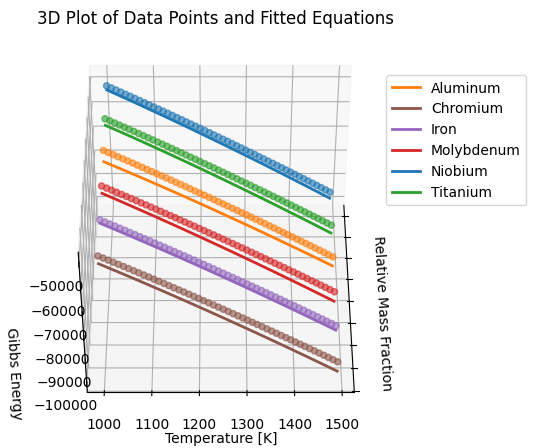

In [38]:
# Define dataset points
mole_frac_value_true = full_d_list_true[:, 0]
temperature_true = full_d_list_true[:, 1]
gibbs_energy_true = full_d_list_true[:, 2]
temp_class_num_true = full_d_list_true[:, 3]


mole_frac_value_std = full_d_list_std[:, 0]
temperature_std = full_d_list_std[:, 1]
gibbs_energy_std = full_d_list_std[:, 2]
temp_class_num_std = full_d_list_std[:, 3]


from sklearn.metrics import mean_absolute_percentage_error

# Define prediction functions for each class (using your equations)
# non_weird_full_eq = {
#     'nb': lambda x0, x1: 1.0291201**(x0 - 0.20558353) * (-x0 + (x1 - 0.25470167 * (x1**2 + 0.2880812)) * (-0.08940733)),
#     'al': lambda x0, x2: 1.03156938690521**(x0 - 0.66138196 * x2 - 1.679607) * (0.39183077 * 0.49847025**x2 - x0 - 0.468932133457517),
#     'ti': lambda x0, x3: 0.9681053**(-x0 + 0.36640376 * x3 + 0.411415692468104) * (-x0 + 0.23432513 * np.sqrt(0.29113433**x3) - 0.24907888),
#     'mo': lambda x0, x4: -0.032634176 * x0**2 - x0 + 0.032634176 * (1.19726768101373 * 0.86230316016784**(x0 - x4))**x4 - 0.0064035367562368,
#     'fe': lambda x0, x5: -0.032786813 * x0**2 - x0 + 0.032786813 * np.sqrt((0.8917202**(x0 + 1.72557701786078))**(3 * x5 / 2)),
#     'cr': lambda x0, x6: -x0 + (x0**2 - x6 - (0.950945**x0 - 1 * 0.22067341)**x6) * (-0.017228598) / 0.5418049,
# }


# Define class-specific data
color_dict = {'nb': 0, 'al': 1,  'ti': 2, 'mo': 3, 'fe': 4, 'cr': 5}
vars_dict = {'nb': x1, 'al': x2, 'ti': x3, 'mo': x4, 'fe': x5, 'cr': x6}
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']


separation_factor = 0.0


#
#     print(mean_absolute_percentage_error(gibbs_points_true, predictions_no_std))
first_idx = 50

# Create 3D scatter plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')



SIMPLIFIED_EQS_LINEAR_REG = {
    'nb': (-0.0001193602 - 0.9956103292 *  x0 - 0.0885575985 * x1),
    # 'nb': (-0.0001193602 - 0.956103292 *  x0 - 0.0885575985 * x1),
    # 'al': 0.003309356 - 0.9518593309* x0 - 0.2967325221 * x2,
    # 'ti': 0.0002545829 - 0.9853086363 * x0 - 0.1596380125 * x3,
    # 'mo': -0.000111233 - 0.9983875511 * x0 + 0.0091461976 * x4,
    'fe': -0.0013468665 - 0.999387069 * x0 - 0.0059619962 * x5,  # Simplified with assumptions
    # 'fe': -x0 + 0.0323 *  * x0**2 + 0.00302 *  * x0 * x5 + 0.00086 * x5**2 - 0.0323 * exp(-0.1797 * x5),
    # 'cr': - * x0 -  * x0**2 * 0.0323 + x6 * sin(sin(0.8701099**( * x0 - x6))) * 0.0323 + 0.0305
    'cr': -0.0013327899 - 0.9991415915 * x0 + 0.0239212818 * x6,
}

non_weird_full_eq = {
    'nb': 1.0291201**(x0 - 0.20558353)*(-x0 + (x1 - 0.25470167*(x1**2 + 0.2880812))*(-0.08940733)),
    'al': 1.03156938690521**(x0 - 0.66138196*x2 - 1.679607)*(0.39183077*0.49847025**x2 - x0 - 0.468932133457517), # sp.log = exp = e^(x)
    'ti': 0.9681053**(-x0 + 0.36640376*x3 + 0.411415692468104)*(-x0 + 0.23432513*sp.sqrt(0.29113433**x3) - 0.24907888),
    'mo': -0.032634176*x0**2 - x0 + 0.032634176*(1.19726768101373*0.86230316016784**(x0 - x4))**x4 - 0.0064035367562368, 
    'fe': -0.032786813*x0**2 - x0 + 0.032786813*sp.sqrt((0.8917202**(x0 + 1.72557701786078))**(3*x5/2)), 
    'cr': -x0 + (x0**2 - x6 - (0.950945**x0 - 1*0.22067341)**x6)*(-0.017228598)/0.5418049
}

POLYNOMIAL_DEG5 = {
    'al': 0.00022297064*x0**5 - 0.0001725261935*x0**4*x2 - 0.0004323525391*x0**4 - 0.0001350684923*x0**3*x2**2 + 0.0003510015678*x0**3*x2 + 0.0006112774501*x0**3 + 0.000263447443*x0**2*x2**3 + 8.393239196e-5*x0**2*x2**2 + 0.0002406736679*x0**2*x2 - 0.03036403927*x0**2 + 0.001031157441*x0*x2**4 - 0.002264061766*x0*x2**3 - 0.001423870068*x0*x2**2 + 0.01525183492*x0*x2 - 0.952561335*x0 - 0.002995895608*x2**5 + 0.005085888584*x2**4 - 0.006931878943*x2**3 + 0.0917637839*x2**2 - 0.2719830749*x2 - 0.06974885634,
    'cr': 8.95949866e-6*x0**5 + 2.015854531e-6*x0**4*x6 - 0.000128821316*x0**4 - 5.112659721e-7*x0**3*x6**2 - 4.981593644e-6*x0**3*x6 + 0.0007788523850*x0**3 - 6.554422716e-7*x0**2*x6**3 + 1.942044057e-7*x0**2*x6**2 - 3.680291928e-5*x0**2*x6 - 0.03256534615*x0**2 + 7.544579277e-7*x0*x6**4 - 8.703718994e-6*x0*x6**3 + 0.0003880880444*x0*x6**2 - 0.001671849037*x0*x6 - 1.001095426*x0 - 7.78617207e-7*x6**5 + 7.212851862e-6*x6**4 - 0.0001234494179*x6**3 + 0.002602454752*x6**2 + 0.02440850088*x6 + 0.03018186235,
    'fe': 1.024748554e-5*x0**5 + 1.174617339e-7*x0**4*x5 - 0.0001297540025*x0**4 + 5.631318705e-7*x0**3*x5**2 + 1.546991364e-6*x0**3*x5 + 0.0007768222507*x0**3 - 2.774433697e-7*x0**2*x5**3 - 9.271069746e-8*x0**2*x5**2 - 2.150483909e-5*x0**2*x5 - 0.03257497328*x0**2 + 1.905081412e-6*x0*x5**4 - 7.936603919e-6*x0*x5**3 + 0.0002380719093*x0*x5**2 - 0.003007828769*x0*x5 - 1.001223954*x0 - 6.663783499e-7*x5**5 + 7.163977651e-6*x5**4 - 8.553147397e-5*x5**3 + 0.002293564185*x5**2 - 0.005533205496*x5 + 0.03050209251,
    'mo': 5.285148504e-6*x0**5 + 5.317202676e-7*x0**4*x4 - 0.0001318704932*x0**4 - 3.203785006e-6*x0**3*x4**2 + 1.571194245e-5*x0**3*x4 + 0.0008070588136*x0**3 + 1.739120272e-6*x0**2*x4**3 + 8.296990147e-6*x0**2*x4**2 + 0.0002096711912*x0**2*x4 - 0.03209771148*x0**2 + 0.0001832330458*x0*x4**4 - 0.0003699061969*x0*x4**3 + 0.0006209069523*x0*x4**2 - 0.005639730148*x0*x4 - 1.001880453*x0 - 0.0006950845291*x4**5 + 0.001144612591*x4**4 + 0.000245527907*x4**3 + 0.008647032695*x4**2 + 0.0108465114*x4 + 0.02162983338,
    'nb': 1.237512366e-5*x0**5 - 1.414868568e-5*x0**4*x1 - 0.0001183929248*x0**4 - 1.084077549e-6*x0**3*x1**2 + 1.363942444e-5*x0**3*x1 + 0.0007788773043*x0**3 - 5.296755066e-6*x0**2*x1**3 + 1.417736463e-5*x0**2*x1**2 + 0.0003513433909*x0**2*x1 - 0.03206369925*x0**2 + 0.0002433328254*x0*x1**4 - 0.0003464493798*x0*x1**3 - 0.0007628844867*x0*x1**2 - 0.003183098628*x0*x1 - 0.9964761339*x0 - 0.0008351374166*x1**5 + 0.001357065189*x1**4 + 0.0003631666188*x1**3 + 0.01942190323*x1**2 - 0.08718643598*x1 + 0.01041071969,
    'ti': 0.0003132546293*x0**5 - 0.0005410491076*x0**4*x3 - 0.000804498525*x0**4 - 1.201269319e-5*x0**3*x3**2 + 0.0008227376762*x0**3*x3 + 0.0007864873237*x0**3 + 0.0004388143344*x0**2*x3**3 - 3.363532466e-5*x0**2*x3**2 - 0.0004538157646*x0**2*x3 - 0.03177225254*x0**2 + 0.0002789284072*x0*x3**4 - 0.001020770524*x0*x3**3 - 0.0003406220097*x0*x3**2 + 0.004318081062*x0*x3 - 0.9884768197*x0 - 0.001560453248*x3**5 + 0.002586336888*x3**4 - 0.002336656202*x3**3 + 0.04266292439*x3**2 - 0.1487410549*x3 - 0.01405843192,
}


general_lin_reg = 40538.6564956021 + -2.44081552e+04 * x1 + -1.24728427e+05 * x2 + -6.79061879e+04 * x3 + 5.54777564e+03 * x4 + -2.18735182e+03 * x5 + 2.42974739e+04 * x6 + -9.44323379e+01 * x0

use_equations = POLYNOMIAL_DEG5


def general_lin_reg(x1, x2, x3, x4, x5, x6, x0):
    return 40538.6564956021 + (-2.44081552e+04 * x1) + (-1.24728427e+05 * x2) + (-6.79061879e+04 * x3) + (5.54777564e+03 * x4) + (-2.18735182e+03 * x5) + (2.42974739e+04 * x6) + (-9.44323379e+01 * x0)


element_translation = {
    'nb': 'Niobium',
    'al': 'Aluminum',
    'ti': 'Titanium',
    'mo': 'Molybdenum',
    'fe': 'Iron',
    'cr': 'Chromium'
}

# Loop through classes to process data and calculate predictions
for class_name, func in use_equations.items():
    class_idx = color_dict[class_name]
    
    # True (non-standardized) data points
    mask_true = temp_class_num_true == class_idx
    mole_frac_true = mole_frac_value_true[mask_true][:first_idx] + class_idx * separation_factor
    temperature_points_true = temperature_true[mask_true][:first_idx] + class_idx * separation_factor
    gibbs_points_true = gibbs_energy_true[mask_true][:first_idx]
    
    # Standardized data points
    mask_std = temp_class_num_std == class_idx
    mole_frac_std = mole_frac_value_std[mask_std][:first_idx] + class_idx * separation_factor
    temperature_points_std = temperature_std[mask_std][:first_idx] + class_idx * separation_factor
    
    if class_name == 'fe':
        mole_frac_true = mole_frac_true - 0.03
        
    if class_name == 'mo':
        mole_frac_true = mole_frac_true + 0.09
        
    if class_name == 'al':
        mole_frac_true = mole_frac_true + 0.06
        
    if class_name == 'ti':
        mole_frac_true = mole_frac_true + 0.03
        
    
    # Scatter true data points
    ax.scatter(
        mole_frac_true, 
        temperature_points_true, 
        gibbs_points_true, 
        color=colors[class_idx], 
        # label=f'{element_translation[class_name]} Data', 
        s=20, 
        alpha=0.6
    )
    
    # Prepare points for symbolic evaluation
    points = np.stack([temperature_points_std, mole_frac_std], axis=1)
    predictions = []
    
    # Evaluate the symbolic function for each point
    for point in points:
        # Create a dictionary for symbolic evaluation
        point_dict = {x0: point[0], vars_dict[class_name]: point[1]}  # Adjust this for your variables
        prediction = func.evalf(subs=point_dict)
        predictions.append(prediction)
    
    # Convert predictions to array
    predictions = np.array(predictions, dtype=float).reshape(-1, 1)
    predictions_no_std = (y_scaler.inverse_transform(predictions) + class_idx * separation_factor).flatten()
    
    # Plot predictions as a line
    ax.plot(
        mole_frac_true, 
        temperature_points_true, 
        predictions_no_std, 
        color=colors[class_idx], 
        label=f'{element_translation[class_name]}', 
        linewidth=2
    )
    
    
    
    
    # Print MAPE for each class
    mape = mean_absolute_percentage_error(gibbs_points_true, predictions_no_std)
    print(f'MAPE for class {class_name}: {mape:.4f}')



# Relabel the x-axis and remove tick labels
ax.set_xlabel('Relative Mass Fraction', labelpad=0)  # Add padding for better spacing
ax.set_xticklabels([])  # Remove numerical labels on the x-axis

# Adjust y-axis label with padding
ax.set_ylabel('Temperature [K]', labelpad=0)  # Add padding to prevent cut-off

# Adjust z-axis label with padding
ax.set_zlabel('Gibbs Energy', labelpad=15)  # Add padding to avoid overlap with numbers
ax.zaxis.set_label_coords(-0.1, 1)

# Adjust the legend position to avoid overlap
ax.legend(loc='upper left', bbox_to_anchor=(0.9, 0.9))  # Move legend further outside the plot

# Use tight layout for better spacing and prevent labels from being cut off
plt.tight_layout(pad=2.5)  # Increase padding for tighter layout adjustments

# Set the title
ax.set_title('3D Plot of Data Points and Fitted Equations', pad=2)  # Add padding for title spacing

# Adjust the viewing angle
ax.view_init(elev=45, azim=0)

plt.show()




MAPE for class al: 0.0612
MAPE for class cr: 0.0494
MAPE for class fe: 0.0229
MAPE for class mo: 0.0488
MAPE for class nb: 0.0302
MAPE for class ti: 0.0422


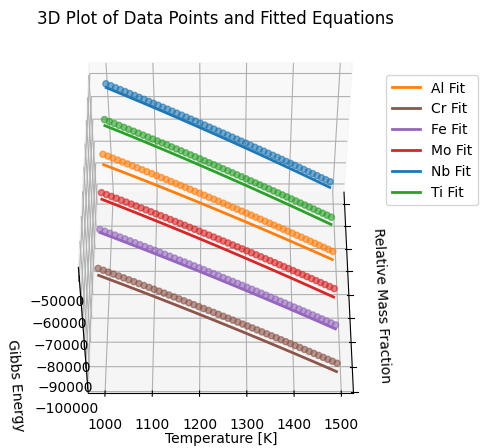

In [34]:
# Define dataset points
mole_frac_value_true = full_d_list_true[:, 0]
temperature_true = full_d_list_true[:, 1]
gibbs_energy_true = full_d_list_true[:, 2]
temp_class_num_true = full_d_list_true[:, 3]


mole_frac_value_std = full_d_list_std[:, 0]
temperature_std = full_d_list_std[:, 1]
gibbs_energy_std = full_d_list_std[:, 2]
temp_class_num_std = full_d_list_std[:, 3]


from sklearn.metrics import mean_absolute_percentage_error

# Define prediction functions for each class (using your equations)
# non_weird_full_eq = {
#     'nb': lambda x0, x1: 1.0291201**(x0 - 0.20558353) * (-x0 + (x1 - 0.25470167 * (x1**2 + 0.2880812)) * (-0.08940733)),
#     'al': lambda x0, x2: 1.03156938690521**(x0 - 0.66138196 * x2 - 1.679607) * (0.39183077 * 0.49847025**x2 - x0 - 0.468932133457517),
#     'ti': lambda x0, x3: 0.9681053**(-x0 + 0.36640376 * x3 + 0.411415692468104) * (-x0 + 0.23432513 * np.sqrt(0.29113433**x3) - 0.24907888),
#     'mo': lambda x0, x4: -0.032634176 * x0**2 - x0 + 0.032634176 * (1.19726768101373 * 0.86230316016784**(x0 - x4))**x4 - 0.0064035367562368,
#     'fe': lambda x0, x5: -0.032786813 * x0**2 - x0 + 0.032786813 * np.sqrt((0.8917202**(x0 + 1.72557701786078))**(3 * x5 / 2)),
#     'cr': lambda x0, x6: -x0 + (x0**2 - x6 - (0.950945**x0 - 1 * 0.22067341)**x6) * (-0.017228598) / 0.5418049,
# }


# Define class-specific data
color_dict = {'nb': 0, 'al': 1,  'ti': 2, 'mo': 3, 'fe': 4, 'cr': 5}
vars_dict = {'nb': x1, 'al': x2, 'ti': x3, 'mo': x4, 'fe': x5, 'cr': x6}
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

# Plot points and predictions


# # Loop through classes
# for class_name, func in non_weird_full_eq.items():
#     class_idx = color_dict[class_name]
#     mask = temp_class_num == class_idx

#     # Data points for the class
#     x0 = mole_frac_value[mask]
#     temperature_points = temperature[mask]
#     gibbs_points = gibbs_energy[mask]
#     color = colors[class_idx]

#     # Scatter the original data points
#     ax.scatter(x0, temperature_points, gibbs_points, color=color, label=f'{class_name} Data', s=30, alpha=0.6)

#     # Generate predictions
#     predictions = func(x0, temperature_points)
#     predictions_no_std = y_scaler.inverse_transform(predictions.reshape(-1, 1))

#     # Plot predictions as a line
#     # ax.plot(x0, temperature_points, predictions_no_std, color=color, label=f'{class_name} Fit', linewidth=2)

# Separation factor for better visualization


# fig = plt.figure()
# ax = fig.add_subplot(111, projection='3d')

separation_factor = 0.0


# first_idx = 100

# # # Loop through classes
# for class_name, func in non_weird_full_eq.items():
    
#     class_idx = color_dict[class_name]
#     mask_true = temp_class_num_true == class_idx

#     # Data points for the class
#     mole_frac_true = mole_frac_value_true[mask_true][first_idx] + class_idx * separation_factor  # Offset mole fraction by class index
#     temperature_points_true = temperature_true[mask_true][first_idx] + class_idx * separation_factor  # Offset temperature by class index
#     gibbs_points_true = gibbs_energy_true[mask_true][first_idx]
#     color = colors[class_idx]
    
#     mask_std = temp_class_num_std == class_idx

#     # Data points for the class
#     mole_frac_std = mole_frac_value_std[mask_std][first_idx] + class_idx * separation_factor  # Offset mole fraction by class index
#     temperature_points_std = temperature_std[mask_std][first_idx] + class_idx * separation_factor  # Offset temperature by class index
#     gibbs_points_std = gibbs_energy_std[mask_std][first_idx]
#     color = colors[class_idx]

#     # Scatter the original data points
#     ax.scatter(mole_frac_true, temperature_points_true, gibbs_points_true, color=color, label=f'{class_name} Data', s=30, alpha=0.6)

#     # print(mole_frac_std)

#     # point = np.stack(temperature_points_std, mole_frac_std)

#     # point_dict = {relevant_variables[j]: point[j] for j in range(6)}
    
#     points = np.stack([temperature_points_std, mole_frac_std], axis=1)
    
    
#     predictions = []
    
#     point_length = points.shape[1]
    
#     for point in points:
#         # Create a dictionary for symbolic evaluation
#         # point_dict = {filter_variables[j]: point[j] for j in range(point_length)}
        
#         point_dict = {x0: point[0], vars_dict[class_name]: point[1]}
#         # Evaluate the symbolic function at the given point
#         prediction = func.evalf(subs=point_dict)
        
#         # if prediction == math.nan:
#         #     print(point)
#         #     print(func)
        
#         predictions.append(prediction)

#     # Generate predictions
#     # try:
#     predictions = np.array(predictions, dtype=float).reshape(-1, 1)
#     # except:
#     #     print(predictions)    
    
#     predictions_no_std = y_scaler.inverse_transform(predictions) + class_idx * separation_factor

#     # Plot predictions as a line
#     ax.plot(mole_frac_true, temperature_points_true, predictions_no_std, color=color, label=f'{class_name} Fit', linewidth=2)
    
#     print(mean_absolute_percentage_error(gibbs_points_true, predictions_no_std))
first_idx = 50

# Create 3D scatter plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')



SIMPLIFIED_EQS_LINEAR_REG = {
    'nb': (-0.0001193602 - 0.9956103292 *  x0 - 0.0885575985 * x1),
    # 'nb': (-0.0001193602 - 0.956103292 *  x0 - 0.0885575985 * x1),
    # 'al': 0.003309356 - 0.9518593309* x0 - 0.2967325221 * x2,
    # 'ti': 0.0002545829 - 0.9853086363 * x0 - 0.1596380125 * x3,
    # 'mo': -0.000111233 - 0.9983875511 * x0 + 0.0091461976 * x4,
    'fe': -0.0013468665 - 0.999387069 * x0 - 0.0059619962 * x5,  # Simplified with assumptions
    # 'fe': -x0 + 0.0323 *  * x0**2 + 0.00302 *  * x0 * x5 + 0.00086 * x5**2 - 0.0323 * exp(-0.1797 * x5),
    # 'cr': - * x0 -  * x0**2 * 0.0323 + x6 * sin(sin(0.8701099**( * x0 - x6))) * 0.0323 + 0.0305
    'cr': -0.0013327899 - 0.9991415915 * x0 + 0.0239212818 * x6,
}

non_weird_full_eq = {
    'nb': 1.0291201**(x0 - 0.20558353)*(-x0 + (x1 - 0.25470167*(x1**2 + 0.2880812))*(-0.08940733)),
    'al': 1.03156938690521**(x0 - 0.66138196*x2 - 1.679607)*(0.39183077*0.49847025**x2 - x0 - 0.468932133457517), # sp.log = exp = e^(x)
    'ti': 0.9681053**(-x0 + 0.36640376*x3 + 0.411415692468104)*(-x0 + 0.23432513*sp.sqrt(0.29113433**x3) - 0.24907888),
    'mo': -0.032634176*x0**2 - x0 + 0.032634176*(1.19726768101373*0.86230316016784**(x0 - x4))**x4 - 0.0064035367562368, 
    'fe': -0.032786813*x0**2 - x0 + 0.032786813*sp.sqrt((0.8917202**(x0 + 1.72557701786078))**(3*x5/2)), 
    'cr': -x0 + (x0**2 - x6 - (0.950945**x0 - 1*0.22067341)**x6)*(-0.017228598)/0.5418049
}

POLYNOMIAL_DEG5 = {
    'al': 0.00022297064*x0**5 - 0.0001725261935*x0**4*x2 - 0.0004323525391*x0**4 - 0.0001350684923*x0**3*x2**2 + 0.0003510015678*x0**3*x2 + 0.0006112774501*x0**3 + 0.000263447443*x0**2*x2**3 + 8.393239196e-5*x0**2*x2**2 + 0.0002406736679*x0**2*x2 - 0.03036403927*x0**2 + 0.001031157441*x0*x2**4 - 0.002264061766*x0*x2**3 - 0.001423870068*x0*x2**2 + 0.01525183492*x0*x2 - 0.952561335*x0 - 0.002995895608*x2**5 + 0.005085888584*x2**4 - 0.006931878943*x2**3 + 0.0917637839*x2**2 - 0.2719830749*x2 - 0.06974885634,
    'cr': 8.95949866e-6*x0**5 + 2.015854531e-6*x0**4*x6 - 0.000128821316*x0**4 - 5.112659721e-7*x0**3*x6**2 - 4.981593644e-6*x0**3*x6 + 0.0007788523850*x0**3 - 6.554422716e-7*x0**2*x6**3 + 1.942044057e-7*x0**2*x6**2 - 3.680291928e-5*x0**2*x6 - 0.03256534615*x0**2 + 7.544579277e-7*x0*x6**4 - 8.703718994e-6*x0*x6**3 + 0.0003880880444*x0*x6**2 - 0.001671849037*x0*x6 - 1.001095426*x0 - 7.78617207e-7*x6**5 + 7.212851862e-6*x6**4 - 0.0001234494179*x6**3 + 0.002602454752*x6**2 + 0.02440850088*x6 + 0.03018186235,
    'fe': 1.024748554e-5*x0**5 + 1.174617339e-7*x0**4*x5 - 0.0001297540025*x0**4 + 5.631318705e-7*x0**3*x5**2 + 1.546991364e-6*x0**3*x5 + 0.0007768222507*x0**3 - 2.774433697e-7*x0**2*x5**3 - 9.271069746e-8*x0**2*x5**2 - 2.150483909e-5*x0**2*x5 - 0.03257497328*x0**2 + 1.905081412e-6*x0*x5**4 - 7.936603919e-6*x0*x5**3 + 0.0002380719093*x0*x5**2 - 0.003007828769*x0*x5 - 1.001223954*x0 - 6.663783499e-7*x5**5 + 7.163977651e-6*x5**4 - 8.553147397e-5*x5**3 + 0.002293564185*x5**2 - 0.005533205496*x5 + 0.03050209251,
    'mo': 5.285148504e-6*x0**5 + 5.317202676e-7*x0**4*x4 - 0.0001318704932*x0**4 - 3.203785006e-6*x0**3*x4**2 + 1.571194245e-5*x0**3*x4 + 0.0008070588136*x0**3 + 1.739120272e-6*x0**2*x4**3 + 8.296990147e-6*x0**2*x4**2 + 0.0002096711912*x0**2*x4 - 0.03209771148*x0**2 + 0.0001832330458*x0*x4**4 - 0.0003699061969*x0*x4**3 + 0.0006209069523*x0*x4**2 - 0.005639730148*x0*x4 - 1.001880453*x0 - 0.0006950845291*x4**5 + 0.001144612591*x4**4 + 0.000245527907*x4**3 + 0.008647032695*x4**2 + 0.0108465114*x4 + 0.02162983338,
    'nb': 1.237512366e-5*x0**5 - 1.414868568e-5*x0**4*x1 - 0.0001183929248*x0**4 - 1.084077549e-6*x0**3*x1**2 + 1.363942444e-5*x0**3*x1 + 0.0007788773043*x0**3 - 5.296755066e-6*x0**2*x1**3 + 1.417736463e-5*x0**2*x1**2 + 0.0003513433909*x0**2*x1 - 0.03206369925*x0**2 + 0.0002433328254*x0*x1**4 - 0.0003464493798*x0*x1**3 - 0.0007628844867*x0*x1**2 - 0.003183098628*x0*x1 - 0.9964761339*x0 - 0.0008351374166*x1**5 + 0.001357065189*x1**4 + 0.0003631666188*x1**3 + 0.01942190323*x1**2 - 0.08718643598*x1 + 0.01041071969,
    'ti': 0.0003132546293*x0**5 - 0.0005410491076*x0**4*x3 - 0.000804498525*x0**4 - 1.201269319e-5*x0**3*x3**2 + 0.0008227376762*x0**3*x3 + 0.0007864873237*x0**3 + 0.0004388143344*x0**2*x3**3 - 3.363532466e-5*x0**2*x3**2 - 0.0004538157646*x0**2*x3 - 0.03177225254*x0**2 + 0.0002789284072*x0*x3**4 - 0.001020770524*x0*x3**3 - 0.0003406220097*x0*x3**2 + 0.004318081062*x0*x3 - 0.9884768197*x0 - 0.001560453248*x3**5 + 0.002586336888*x3**4 - 0.002336656202*x3**3 + 0.04266292439*x3**2 - 0.1487410549*x3 - 0.01405843192,
}


general_lin_reg = 40538.6564956021 + -2.44081552e+04 * x1 + -1.24728427e+05 * x2 + -6.79061879e+04 * x3 + 5.54777564e+03 * x4 + -2.18735182e+03 * x5 + 2.42974739e+04 * x6 + -9.44323379e+01 * x0

use_equations = POLYNOMIAL_DEG5


def general_lin_reg(x1, x2, x3, x4, x5, x6, x0):
    return 40538.6564956021 + (-2.44081552e+04 * x1) + (-1.24728427e+05 * x2) + (-6.79061879e+04 * x3) + (5.54777564e+03 * x4) + (-2.18735182e+03 * x5) + (2.42974739e+04 * x6) + (-9.44323379e+01 * x0)


# Loop through classes to process data and calculate predictions
for class_name, func in use_equations.items():
    class_idx = color_dict[class_name]
    
    # True (non-standardized) data points
    mask_true = temp_class_num_true == class_idx
    mole_frac_true = mole_frac_value_true[mask_true][:first_idx] + class_idx * separation_factor
    temperature_points_true = temperature_true[mask_true][:first_idx] + class_idx * separation_factor
    gibbs_points_true = gibbs_energy_true[mask_true][:first_idx]
    
    # Standardized data points
    mask_std = temp_class_num_std == class_idx
    mole_frac_std = mole_frac_value_std[mask_std][:first_idx] + class_idx * separation_factor
    temperature_points_std = temperature_std[mask_std][:first_idx] + class_idx * separation_factor
    
    if class_name == 'fe':
        mole_frac_true = mole_frac_true - 0.03
        
    if class_name == 'mo':
        mole_frac_true = mole_frac_true + 0.09
        
    if class_name == 'al':
        mole_frac_true = mole_frac_true + 0.06
        
    if class_name == 'ti':
        mole_frac_true = mole_frac_true + 0.03
        
    # if class_name == 'mo':
    #     mole_frac_true = mole_frac_true + 0.09
    
    
    # Scatter true data points
    ax.scatter(
        mole_frac_true, 
        temperature_points_true, 
        gibbs_points_true, 
        color=colors[class_idx], 
        # label=f'{class_name} Data', 
        s=20, 
        alpha=0.6
    )
    
    # Prepare points for symbolic evaluation
    points = np.stack([temperature_points_std, mole_frac_std], axis=1)
    predictions = []
    
    # Evaluate the symbolic function for each point
    for point in points:
        # Create a dictionary for symbolic evaluation
        point_dict = {x0: point[0], vars_dict[class_name]: point[1]}  # Adjust this for your variables
        prediction = func.evalf(subs=point_dict)
        predictions.append(prediction)
    
    # Convert predictions to array
    predictions = np.array(predictions, dtype=float).reshape(-1, 1)
    predictions_no_std = (y_scaler.inverse_transform(predictions) + class_idx * separation_factor).flatten()
    
    # Plot predictions as a line
    ax.plot(
        mole_frac_true, 
        temperature_points_true, 
        predictions_no_std, 
        color=colors[class_idx], 
        label=f'{class_name.capitalize()} Fit', 
        linewidth=2
    )
    
    
    
    # ax.scatter(
    #     mole_frac_true, 
    #     temperature_points_true, 
    #     predictions_no_std, 
    #     color=colors[class_idx], 
    #     marker='x', 
    #     # label=f'{class_name} Predictions', 
    #     s=40, 
    #     alpha=0.8
    # )
    
    
    # print(predictions_no_std)
    
    
    # Print MAPE for each class
    mape = mean_absolute_percentage_error(gibbs_points_true, predictions_no_std)
    print(f'MAPE for class {class_name}: {mape:.4f}')

    # print(predictions_no_std.shape)
    # print(gibbs_points_true.shape)
    # print(class_name)
    
# ax.set_xlim(left=0)  # Ensure mole fraction axis starts at 0
# # ax.set_ylim(bottom=0)  # Ensure temperature axis starts at 0
    
# ax.legend()
# ax.set_xlabel('Mole Fraction Value')
# ax.set_ylabel('Temperature [K]')
# ax.set_zlabel('Gibbs Energy')
# ax.set_title('3D Plot of Data Points and Fitted Equations')

# ax.view_init(elev=50, azim=0)

# plt.show()

# Relabel the x-axis and remove tick labels
# ax.set_xlabel('Relative Mass Fraction')
# ax.set_xticklabels([])  # Remove numerical labels on the x-axis

# # Adjust the legend and axes settings as needed
# ax.legend()
# ax.set_ylabel('Temperature [K]')
# ax.set_zlabel('Gibbs Energy')
# ax.set_title('3D Plot of Data Points and Fitted Equations')

# ax.view_init(elev=50, azim=0)

# plt.show()


# # Relabel the x-axis and remove tick labels
# ax.set_xlabel('Relative Mass Fraction')
# ax.set_xticklabels([])  # Remove numerical labels on the x-axis

# # Adjust the legend position to avoid overlap
# ax.legend(loc='upper left', bbox_to_anchor=(0.9, 1.0))  # Move legend outside the plot

# # Ensure the layout adjusts to prevent axes from being cut off
# plt.tight_layout()

# # Set the other labels and title
# ax.set_ylabel('Temperature [K]')
# ax.set_zlabel('Gibbs Energy')
# ax.set_title('3D Plot of Data Points and Fitted Equations')

# # Adjust the viewing angle
# ax.view_init(elev=50, azim=0)

# plt.show()


# general_predictions = general_lin_reg(mole_frac_true, temperature_points_true, gibbs_points_true, gibbs_points_true, mole_frac_true, temperature_points_true, gibbs_points_true) - 1e+6
# ax.plot(
#     mole_frac_true, 
#     temperature_points_true, 
#     general_predictions, 
#     color='black',  # Or use another color to distinguish it
#     label='General Linear Regression', 
#     linewidth=2, 
#     linestyle='--'  
# )


# Relabel the x-axis and remove tick labels
ax.set_xlabel('Relative Mass Fraction', labelpad=0)  # Add padding for better spacing
ax.set_xticklabels([])  # Remove numerical labels on the x-axis

# Adjust y-axis label with padding
ax.set_ylabel('Temperature [K]', labelpad=0)  # Add padding to prevent cut-off

# Adjust z-axis label with padding
ax.set_zlabel('Gibbs Energy', labelpad=15)  # Add padding to avoid overlap with numbers
ax.zaxis.set_label_coords(-0.1, 1)

# Adjust the legend position to avoid overlap
ax.legend(loc='upper left', bbox_to_anchor=(0.9, 0.9))  # Move legend further outside the plot

# Use tight layout for better spacing and prevent labels from being cut off
plt.tight_layout(pad=2.5)  # Increase padding for tighter layout adjustments

# Set the title
ax.set_title('3D Plot of Data Points and Fitted Equations', pad=2)  # Add padding for title spacing

# Adjust the viewing angle
ax.view_init(elev=50, azim=0)

plt.show()




In [ ]:
mole_frac_value_std.shape

(8181,)

In [ ]:
import pickle

file_path = '/home/couchbucks/Documents/saketh/regression/regression/718_all/train_results/saved_models_no_scaled/Linear Regression/Linear Regression_69/Linear Regression_69.pkl'

# Load the pickle file
with open(file_path, 'rb') as file:
    model = pickle.load(file)

# Print the loaded data to inspect
# print(data)


In [ ]:
vars(model)

{'fit_intercept': True,
 'copy_X': True,
 'n_jobs': None,
 'positive': False,
 'n_features_in_': 9,
 'coef_': array([-2.44081552e+04, -1.24728427e+05, -6.79061879e+04,  5.54777564e+03,
        -2.18735182e+03,  3.02988870e+03,  2.42974739e+04, -9.44323379e+01,
         8.06247713e+01]),
 'rank_': 9,
 'singular_': array([1.89629164e+04, 1.30199339e+02, 4.26268523e+00, 3.48934888e+00,
        2.62467295e+00, 2.31393690e+00, 9.34993614e-01, 8.53810123e-01,
        5.49649149e-12]),
 'intercept_': np.float64(40538.6564956021)}

In [ ]:
general_lin_reg = 40538.6564956021 + -2.44081552e+04 * x1 + -1.24728427e+05 * x2 + -6.79061879e+04 * x3 + 5.54777564e+03 * x4 + -2.18735182e+03 * x5 + 2.42974739e+04 * x6 + -9.44323379e+01 * x0

In [ ]:
general_lin_reg

40538.6564956021 - 24408.1552*x0

In [ ]:
from statistics import mean

mean(temperature_std)

np.float64(0.0)

In [ ]:
mole_frac_true

array([0., 0.])

array([0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15,
       0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15,
       0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15,
       0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15,
       0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15,
       0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15,
       0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15,
       0.15, 0.15, 0.15, 0.15, 0.16, 0.16, 0.16, 0.16, 0.16, 0.16, 0.16,
       0.16, 0.16, 0.16, 0.16, 0.16, 0.16, 0.16, 0.16, 0.16, 0.16, 0.16,
       0.16])

IndexError: index 2 is out of bounds for axis 0 with size 2

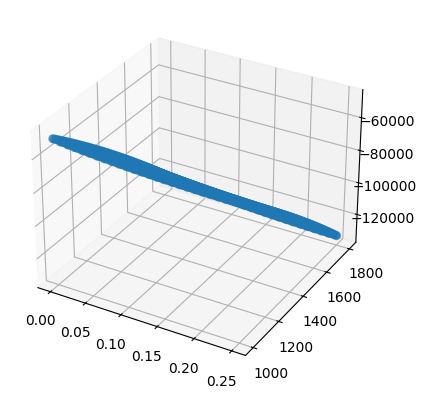

In [ ]:

    

# use_eqs = non_weird_full_eq

# for key in use_eqs:
#     gradients[key] = symbolic_gradient(use_eqs[key], relevant_variables)


# NUMBER_OF_NEIGHBORS = 2

# for class_name, func in non_weird_full_eq.items():
#     class_idx = color_dict[class_name]
    
#     # True (non-standardized) data points
#     mask_true = temp_class_num_true == class_idx
#     mole_frac_true = mole_frac_value_true[mask_true] + class_idx * separation_factor
#     temperature_points_true = temperature_true[mask_true] + class_idx * separation_factor
#     gibbs_points_true = gibbs_energy_true[mask_true]
    
#     # Standardized data points
#     mask_std = temp_class_num_std == class_idx
#     mole_frac_std = mole_frac_value_std[mask_std] + class_idx * separation_factor
#     temperature_points_std = temperature_std[mask_std] + class_idx * separation_factor
    
#     # Scatter true data points
#     ax.scatter(
#         mole_frac_true, 
#         temperature_points_true, 
#         gibbs_points_true, 
#         color=colors[class_idx], 
#         label=f'{class_name} Data', 
#         s=30, 
#         alpha=0.6
#     )
    
#     # Get gradients, distances, weights, and predictions
#     distances, closest_points, gradient_array, gibbs_array = get_neighbors(
#         query_points=np.column_stack([temperature_points_std, mole_frac_std]), 
#         ref_points=ref_points, 
#         all_gradients=all_gradients, 
#         all_gibbs=ref_gibbs, 
#         n=NUMBER_OF_NEIGHBORS, 
#         relative=False, 
#         kdtrees=None,
#         kdtree=None
#     )
    
#     weights = calculate_weight_matrix(distances)
#     predictions_std = predict_gibbs_energy_arrays(
#         np.column_stack([temperature_points_std, mole_frac_std]), 
#         closest_points, 
#         gradient_array, 
#         gibbs_array, 
#         weights, 
#         weighted=True
#     )
    
#     # Transform predictions back to non-standardized space
#     predictions_no_std = y_scaler.inverse_transform(predictions_std.reshape(-1, 1)) + class_idx * separation_factor
    
#     # Plot predictions
#     ax.plot(
#         mole_frac_true, 
#         temperature_points_true, 
#         predictions_no_std, 
#         color='black', 
#         label=f'{class_name} Fit', 
#         linewidth=2
#     )
    
#     # Print MAPE for each class
#     mape = mean_absolute_percentage_error(gibbs_points_true, predictions_no_std)
#     print(f'MAPE for class {class_name}: {mape:.4f}')

# for class_name, func in non_weird_full_eq.items():
#     class_idx = color_dict[class_name]
#     mask = temp_class_num == class_idx

#     # Data points for the class
#     temperature_points = temperature[mask] + class_idx * separation_factor  # Offset temperature by class index (x0 in equations)
#     mole_fractions = mole_frac_value[mask]  # Mole fractions (x1, x2, ..., xn in equations)
#     gibbs_points = gibbs_energy[mask]
#     color = colors[class_idx]

#     # Combine mole fractions into a matrix for function inputs
#     # Assuming mole_frac_value contains all the required x1, x2, ..., xn for the equation
#     equation_inputs = np.column_stack([temperature_points] + [mole_fractions[:, i] for i in range(mole_fractions.shape[1])])

#     # Scatter the original data points
#     ax.scatter(temperature_points, mole_fractions[:, 0], gibbs_points, color=color, label=f'{class_name} Data', s=30, alpha=0.6)

#     # Generate predictions
#     predictions = func(*equation_inputs.T)  # Evaluate the function with the unpacked inputs
#     predictions_no_std = y_scaler.inverse_transform(predictions.reshape(-1, 1))

#     # Plot predictions as a line
#     ax.plot(temperature_points, mole_fractions[:, 0], predictions_no_std, color='black', label=f'{class_name} Fit', linewidth=2)


# Add legend and labels


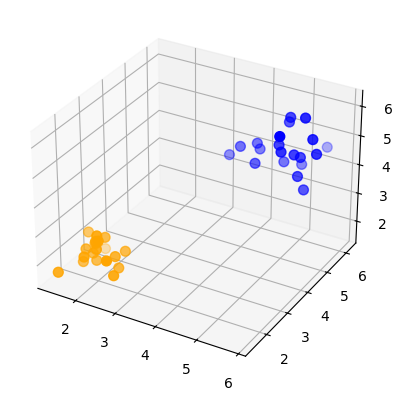

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# Create figure
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Generate orange points
orange_points = np.random.multivariate_normal([2, 2, 2], 0.2 * np.eye(3), size=20)
ax.scatter(orange_points[:, 0], orange_points[:, 1], orange_points[:, 2], color='orange', s=50)

# Generate blue points
blue_points = np.random.multivariate_normal([5, 5, 5], 0.3 * np.eye(3), size=20)
ax.scatter(blue_points[:, 0], blue_points[:, 1], blue_points[:, 2], color='blue', s=50)

# Clean up the plot
# ax.set_box_aspect([1, 1, 1])
# ax.set_xticks([])
# ax.set_yticks([])
# ax.set_zticks([])
# # plt.show()

# # Add the red query point closer to the orange cluster
# red_query_point = [2.5, 2.1, 2.3]
# ax.scatter(*red_query_point, color='red', s=100, label='Query Point')


from scipy.spatial import cKDTree

# Use KDTree to find the 2 nearest orange points to the red query point
# orange_tree = cKDTree(orange_points)
# distances, indices = orange_tree.query(red_query_point, k=2)

# # Highlight the closest points with circles or annotations
# for idx in indices:
#     close_point = orange_points[idx]
#     ax.scatter(*close_point, edgecolor='black', facecolor='orange', s=100, linewidth=2)

# # Draw a circle or equivalent around the red point indicating its neighborhood
# ax.scatter(*red_query_point, color='red', s=100, label='Query Point')

ax.grid('off')

plt.show()


# plt.show()



TypeError: multivariate_normal() got an unexpected keyword argument 'seed'

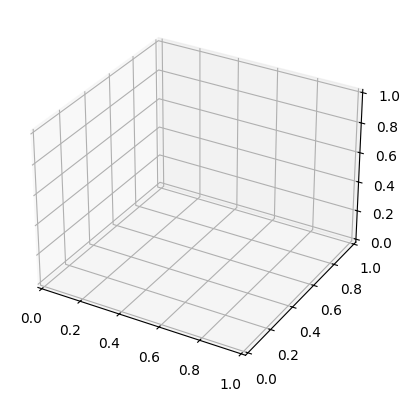

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np
from scipy.spatial import cKDTree

# Create figure
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Generate orange points
orange_points = np.random.multivariate_normal([2, 2, 2], 0.2 * np.eye(3), size=20)
ax.scatter(orange_points[:, 0], orange_points[:, 1], orange_points[:, 2], color='orange', s=50)

# Generate blue points
blue_points = np.random.multivariate_normal([5, 5, 5], 0.3 * np.eye(3), size=20)
ax.scatter(blue_points[:, 0], blue_points[:, 1], blue_points[:, 2], color='blue', s=50)

# Add the red query point closer to the orange cluster
red_query_point = [3, 2.1, 2.8]
ax.scatter(*red_query_point, color='red', s=100, label='Query Point')

# # Use KDTree to find the 2 nearest orange points to the red query point
orange_tree = cKDTree(orange_points)
distances, indices = orange_tree.query(red_query_point, k=2)

# Highlight the closest points with circles
for idx in indices:
    close_point = orange_points[idx]
    ax.scatter(*close_point, edgecolor='black', facecolor='orange', s=100, linewidth=2)

# # Remove gridlines and ticks
ax.grid(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])
ax.set_box_aspect([1, 1, 1])  # Equal aspect ratio

# Show the plot
plt.show()


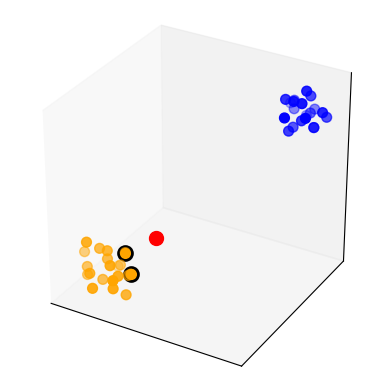

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np
from scipy.spatial import cKDTree

# Fixed seed for reproducibility
np.random.seed(42)

# Fixed orange points
orange_points = np.array([
    [2.0, 2.1, 2.2],
    [1.8, 2.0, 2.1],
    [2.2, 1.9, 2.0],
    [2.1, 2.2, 2.1],
    [2.0, 1.8, 2.0],
    [1.9, 2.1, 2.3],
    [2.2, 2.0, 2.1],
    [1.7, 2.1, 2.2],
    [2.0, 2.3, 2.0],
    [2.3, 2.0, 1.9],
    [1.8, 2.0, 2.4],
    [2.2, 2.2, 2.0],
    [1.9, 1.9, 2.1],
    [2.1, 2.0, 2.2],
    [2.0, 2.1, 2.3],
    [2.1, 2.3, 2.2],
    [2.0, 2.0, 2.0],
    [2.2, 1.9, 2.1],
    [1.8, 2.0, 2.0],
    [2.3, 2.1, 2.1]
])

# Fixed blue points
blue_points_old = np.array([
    [5.2, 5.1, 5.0],
    [4.9, 5.0, 5.3],
    [5.1, 5.2, 5.1],
    [5.0, 4.8, 5.2],
    [5.3, 5.2, 5.1],
    [5.1, 5.1, 5.4],
    [4.8, 5.3, 5.1],
    [5.0, 4.9, 5.0],
    [5.1, 5.0, 5.3],
    [5.3, 5.1, 5.2],
    [4.9, 5.2, 5.1],
    [5.0, 5.3, 5.0],
    [5.2, 5.1, 5.0],
    [5.1, 5.0, 5.1],
    [5.2, 4.9, 5.2],
    [5.1, 5.2, 5.3],
    [5.0, 5.0, 5.0],
    [5.1, 5.3, 5.1],
    [4.9, 5.2, 5.2],
    [5.0, 5.0, 5.3]
])

blue_points_updated = []

for x in blue_points_old:
    # print(x-3)
    
    new_list = [float(a-1.5) for a in x]
    
    blue_points_updated.append(new_list)

blue_points = np.array(blue_points_updated)

# print(blue_points)

# Red query point
red_query_point = [2.5, 2.3, 2.5]

# Plot setup
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Scatter orange and blue points
ax.scatter(orange_points[:, 0], orange_points[:, 1], orange_points[:, 2], color='orange', s=50)
ax.scatter(blue_points[:, 0], blue_points[:, 1], blue_points[:, 2], color='blue', s=50)

# Scatter the red query point
ax.scatter(*red_query_point, color='red', s=100, label='Query Point')

# # KDTree for nearest neighbors
orange_tree = cKDTree(orange_points)
distances, indices = orange_tree.query(red_query_point, k=2)

# Highlight the closest orange points
for idx in indices:
    close_point = orange_points[idx]
    ax.scatter(*close_point, edgecolor='black', facecolor='orange', s=100, linewidth=2)

# Remove gridlines and ticks
ax.grid(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])
ax.set_box_aspect([1, 1, 1])  # Equal aspect ratio

# Show the plot
plt.show()


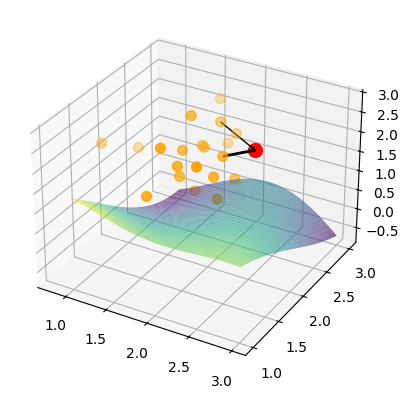

In [ ]:
from matplotlib import cm

# Define a smooth random 3D function
def smooth_function(x, y):
    return np.sin(x) + np.cos(y) + 0.5 * np.sin(2 * x + y)

# Generate meshgrid for the smooth function
x = np.linspace(1, 3, 50)
y = np.linspace(1, 3, 50)
x, y = np.meshgrid(x, y)
z = smooth_function(x, y)

# Plot the orange points
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(orange_points[:, 0], orange_points[:, 1], orange_points[:, 2], color='orange', s=50)

# Add the smooth function
ax.plot_surface(x, y, z, cmap=cm.viridis, alpha=0.6)

# Add the red query point
ax.scatter(*red_query_point, color='red', s=100)

# Draw vectors from the closest orange points to the red query point
for idx, thick in zip(indices, [2, 1]):  # Make one vector thick, the other thin
    close_point = orange_points[idx]
    vector = np.array(red_query_point) - close_point
    ax.quiver(*close_point, *vector, color='black', linewidth=thick, arrow_length_ratio=0.1)

plt.show()



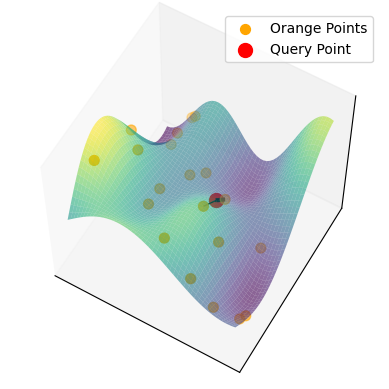

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm

# Generate synthetic orange points around a smooth function
def true_function(x, y):
    """Smooth function with peaks and valleys."""
    return np.sin(np.sqrt(x**2 + y**2)) + np.cos(2 * x) * np.sin(y)

# Generate orange points around the function
np.random.seed(42)  # For reproducibility
x_orange = np.random.uniform(0, 5, 20)
y_orange = np.random.uniform(0, 5, 20)
z_orange = true_function(x_orange, y_orange) + np.random.normal(0, 0.1, 20)  # Add slight noise

# Red query point
red_query_point = [3, 2.5, true_function(3, 2.5)]

# Set up the 3D figure
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot the smooth function surface
x = np.linspace(0, 5, 50)
y = np.linspace(0, 5, 50)
x, y = np.meshgrid(x, y)
z = true_function(x, y)
ax.plot_surface(x, y, z, cmap=cm.viridis, alpha=0.6)

# Plot orange points
ax.scatter(x_orange, y_orange, z_orange, color='orange', s=50, label='Orange Points')

# Plot the red query point
ax.scatter(*red_query_point, color='red', s=100, label='Query Point')

# Highlight the two nearest neighbors to the red query point
distances = np.sqrt((x_orange - red_query_point[0])**2 + (y_orange - red_query_point[1])**2)
nearest_indices = np.argsort(distances)[:2]

for idx, thickness in zip(nearest_indices, [3, 1]):
    close_point = [x_orange[idx], y_orange[idx], z_orange[idx]]
    vector = np.array(red_query_point) - np.array(close_point)
    ax.quiver(*close_point, *vector, color='black', linewidth=thickness, arrow_length_ratio=0.1)

# Customize the plot
ax.set_box_aspect([1, 1, 1])
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])

ax.view_init(elev=60, azim=300)

plt.legend()
plt.show()


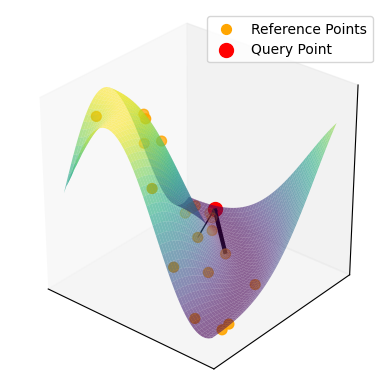

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm

# Generate synthetic orange points around a simplified smooth function
def true_function(x, y):
    """Simplified smooth function with fewer peaks and valleys."""
    return np.sin(np.sqrt(x**2 + y**2))

# Generate orange points around the function
np.random.seed(42)  # For reproducibility
x_orange = np.random.uniform(0, 5, 20)
y_orange = np.random.uniform(0, 5, 20)
z_orange = true_function(x_orange, y_orange) + np.random.normal(0, 0.05, 20)  # Add slight noise

# Red query point slightly above the surface
red_query_point = [3, 2.5, true_function(3, 2.5) + 0.5]

# Set up the 3D figure
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot the smooth function surface
x = np.linspace(0, 5, 50)
y = np.linspace(0, 5, 50)
x, y = np.meshgrid(x, y)
z = true_function(x, y)
ax.plot_surface(x, y, z, cmap=cm.viridis, alpha=0.6)

# Plot orange points
ax.scatter(x_orange, y_orange, z_orange, color='orange', s=50, label='Reference Points')

# Plot the red query point
ax.scatter(*red_query_point, color='red', s=100, label='Query Point')

# Highlight the two nearest neighbors to the red query point
distances = np.sqrt((x_orange - red_query_point[0])**2 + (y_orange - red_query_point[1])**2)
nearest_indices = np.argsort(distances)[:2]

for idx, thickness in zip(nearest_indices, [3, 1]):
    close_point = [x_orange[idx], y_orange[idx], z_orange[idx]]
    vector = np.array(red_query_point) - np.array(close_point)
    ax.quiver(
        close_point[0], close_point[1], close_point[2],  # Start of vector
        vector[0], vector[1], vector[2],  # Direction of vector
        color='black', linewidth=thickness, arrow_length_ratio=0.1
    )

# Customize the plot
ax.set_box_aspect([1, 1, 1])
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])

ax.view_init(elev=30, azim=310)

plt.legend()
plt.show()


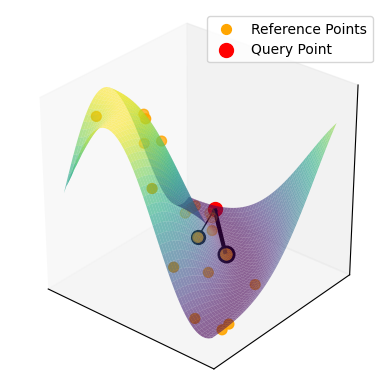

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm

# Generate synthetic orange points around a simplified smooth function
def true_function(x, y):
    """Simplified smooth function with fewer peaks and valleys."""
    return np.sin(np.sqrt(x**2 + y**2))

# Generate orange points around the function
np.random.seed(42)  # For reproducibility
x_orange = np.random.uniform(0, 5, 20)
y_orange = np.random.uniform(0, 5, 20)
z_orange = true_function(x_orange, y_orange) + np.random.normal(0, 0.05, 20)  # Add slight noise

# Red query point slightly above the surface
red_query_point = [3, 2.5, true_function(3, 2.5) + 0.5]

# Set up the 3D figure
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot the smooth function surface
x = np.linspace(0, 5, 50)
y = np.linspace(0, 5, 50)
x, y = np.meshgrid(x, y)
z = true_function(x, y)
ax.plot_surface(x, y, z, cmap=cm.viridis, alpha=0.6)

# Plot orange points
ax.scatter(x_orange, y_orange, z_orange, color='orange', s=50, label='Reference Points')

# Plot the red query point
ax.scatter(*red_query_point, color='red', s=100, label='Query Point')

# Highlight the two nearest neighbors to the red query point
distances = np.sqrt((x_orange - red_query_point[0])**2 + (y_orange - red_query_point[1])**2)
nearest_indices = np.argsort(distances)[:2]

# Plot nearest neighbors with boldness
for idx, size in zip(nearest_indices, [120, 80]):  # Larger size for boldness
    close_point = [x_orange[idx], y_orange[idx], z_orange[idx]]
    ax.scatter(*close_point, color='orange', edgecolor='black', s=size, linewidth=2)

# Draw vectors from neighbors to the red query point
for idx, thickness in zip(nearest_indices, [3, 1]):
    close_point = [x_orange[idx], y_orange[idx], z_orange[idx]]
    vector = np.array(red_query_point) - np.array(close_point)
    ax.quiver(
        close_point[0], close_point[1], close_point[2],  # Start of vector
        vector[0], vector[1], vector[2],  # Direction of vector
        color='black', linewidth=thickness, arrow_length_ratio=0.1
    )

# Customize the plot
ax.set_box_aspect([1, 1, 1])
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])
ax.view_init(elev=30, azim=310)

plt.legend()
plt.show()


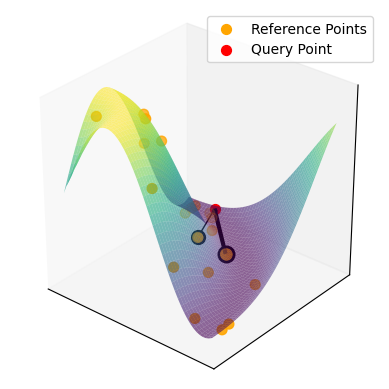

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm

# Generate synthetic orange points around a simplified smooth function
def true_function(x, y):
    """Simplified smooth function with fewer peaks and valleys."""
    return np.sin(np.sqrt(x**2 + y**2))

# Generate orange points around the function
np.random.seed(42)  # For reproducibility
x_orange = np.random.uniform(0, 5, 20)
y_orange = np.random.uniform(0, 5, 20)
z_orange = true_function(x_orange, y_orange) + np.random.normal(0, 0.05, 20)  # Add slight noise

# Red query point slightly above the surface
red_query_point = [3, 2.5, true_function(3, 2.5) + 0.5]

# Set up the 3D figure
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot the smooth function surface
x = np.linspace(0, 5, 50)
y = np.linspace(0, 5, 50)
x, y = np.meshgrid(x, y)
z = true_function(x, y)
ax.plot_surface(x, y, z, cmap=cm.viridis, alpha=0.6)

# Plot orange points
orange_scatter = ax.scatter(x_orange, y_orange, z_orange, color='orange', s=50, label='Reference Points')

# Plot the red query point
# Red query point same size as reference points for consistent legend size
query_scatter = ax.scatter(*red_query_point, color='red', s=50, label='Query Point')

# Highlight the two nearest neighbors to the red query point
distances = np.sqrt((x_orange - red_query_point[0])**2 + (y_orange - red_query_point[1])**2)
nearest_indices = np.argsort(distances)[:2]

# Plot nearest neighbors with boldness
for idx, size in zip(nearest_indices, [120, 80]):  # Larger size for boldness
    close_point = [x_orange[idx], y_orange[idx], z_orange[idx]]
    ax.scatter(*close_point, color='orange', edgecolor='black', s=size, linewidth=2)

# Draw vectors from neighbors to the red query point
for idx, thickness in zip(nearest_indices, [3, 1]):
    close_point = [x_orange[idx], y_orange[idx], z_orange[idx]]
    vector = np.array(red_query_point) - np.array(close_point)
    ax.quiver(
        close_point[0], close_point[1], close_point[2],  # Start of vector
        vector[0], vector[1], vector[2],  # Direction of vector
        color='black', linewidth=thickness, arrow_length_ratio=0.1
    )

# Customize the plot
ax.set_box_aspect([1, 1, 1])
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])
ax.view_init(elev=30, azim=310)

plt.legend()
plt.show()
